# **Лабораторная работа №5. Оценка глубины по изображению**
### **Работу выполнила студентка 2 курса магистратуры группы КомЗр24 Бобина Татьяна Сергеевна**

В этой лабораторной работе вы познакомитесь с двумя основными подходами к оценке глубины
и расстояния до объектов: используя нейросетевые модели для получения карты глубины по
одному изображению, и используя геометрические методы стереовидения. Работа состоит из
теоретического раздела и практических заданий. Пожалуйста, внимательно прочитайте теоретические
сведения, так как они помогут корректно выполнить задания.


## Теоретические сведения

### Нейросетевой подход

Современные нейросетевые модели позволяют восстанавливать карту глубины по одному изображению.  
Например, модель **MiDaS** (Monocular Depth Approximation System), разработанная компанией Intel,
использует глубокие нейронные сети для получения плотной карты глубины из одиночного изображения.  
Она обучена на большом и разнообразном наборе данных, поэтому способна обобщаться на новые сцены.  

Важно: выход MiDaS представляет **относительную** глубину. Это значит, что модель показывает,
какие объекты расположены ближе или дальше друг от друга, но не даёт абсолютных значений расстояния.  
Для получения метрической глубины требуется калибровка — например, по известным размерам объектов.

### Геометрический подход и модель камеры

Для оценки расстояния можно использовать геометрию камеры.  
В рамках **модели отверстия (pinhole camera)** высота объекта $Y$ и его проекция $y$ на матрице
связаны пропорцией:

$$
\frac{Y}{Z} = \frac{y}{f},
$$

где $Z$ — расстояние до объекта, $f$ — фокусное расстояние. Из неё следует $y = fY/Z$.

Если известны реальные размеры объекта и параметры камеры, расстояние вычисляется по формуле:

$$
\text{distance (мм)} =
\frac{f(мм) \times real\_height(мм) \times image\_height(пикс)}
{object\_height(пикс) \times sensor\_height(мм)}.
$$

Здесь:
- *real_height* — реальная высота объекта,  
- *image_height* — высота всего изображения в пикселях,  
- *object_height* — высота объекта в пикселях (например, из bounding box),  
- *f* — фокусное расстояние,  
- *sensor_height* — высота сенсора камеры.

### Стереовидение и диспаритет

Стереовидение основано на сравнении изображений с двух камер, расположенных на базисе $B$.  
Соответствующие точки на левом и правом изображениях смещены на величину **диспаритета** $d$.  

Расстояние до точки вычисляется так:

$$
Z = \frac{f \times B}{d},
$$

где $f$ — фокусное расстояние в пикселях, $B$ — расстояние между камерами (в метрах),
а $d$ — горизонтальное смещение точки между изображениями.  
Формула корректна для выровненных (*rectified*) стереопар, когда эпиполярные линии горизонтальны.



## **Задание 1. Оценка глубины с помощью нейросети**

В этом задании вы попробуете получить карту глубины по одиночному изображению с помощью
предобученной модели MiDaS. Для этого вам понадобится библиотека **PyTorch** и доступ к интернету для скачивания весов.

1. Выберите или загрузите изображение для анализа. Укажите путь к файлу в переменной `image_path`.
Изображение должно быть цветным (RGB).
2. С помощью `torch.hub.load` загрузите модель MiDaS (рекомендуется модель `'DPT_Large'` или `'MiDaS_small'`). https://pytorch.org/hub/intelisl_midas_v2/
Переведите модель в режим `eval()`.
3. Загрузите необходимые трансформации:
   ```python
   transforms = torch.hub.load('intel-isl/MiDaS', 'transforms')
   transform = transforms.small_transform
   ```
4. Прочитайте изображение с помощью `cv2.imread` и преобразуйте его из BGR в RGB.
Примените трансформации и подайте в модель для получения карты глубины.
5. Интерполируйте результат до исходного размера изображения (например, используя `torch.nn.functional.interpolate`).
6. Нормализуйте полученную карту глубины для визуализации и сохраните её как `depth_map_lab5.jpg`.
Отобразите исходное изображение и карту глубины рядом.
7. Выберите область интереса (bounding box) на изображении, где находится объект с известными размерами (например, человек или автомобиль).
Используя медианное значение глубины в области, оцените расстояние до объекта.
Не забудьте учесть, что MiDaS выдаёт относительные значения; для получения приблизительной
метрической оценки используйте калибровочный коэффициент (подберите эмпирически).

Заполните код в ячейке ниже.


In [1]:
# Задание 1: Оценка глубины с помощью нейросети

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

image_path = '/content/Человек и дом.jpg'

Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


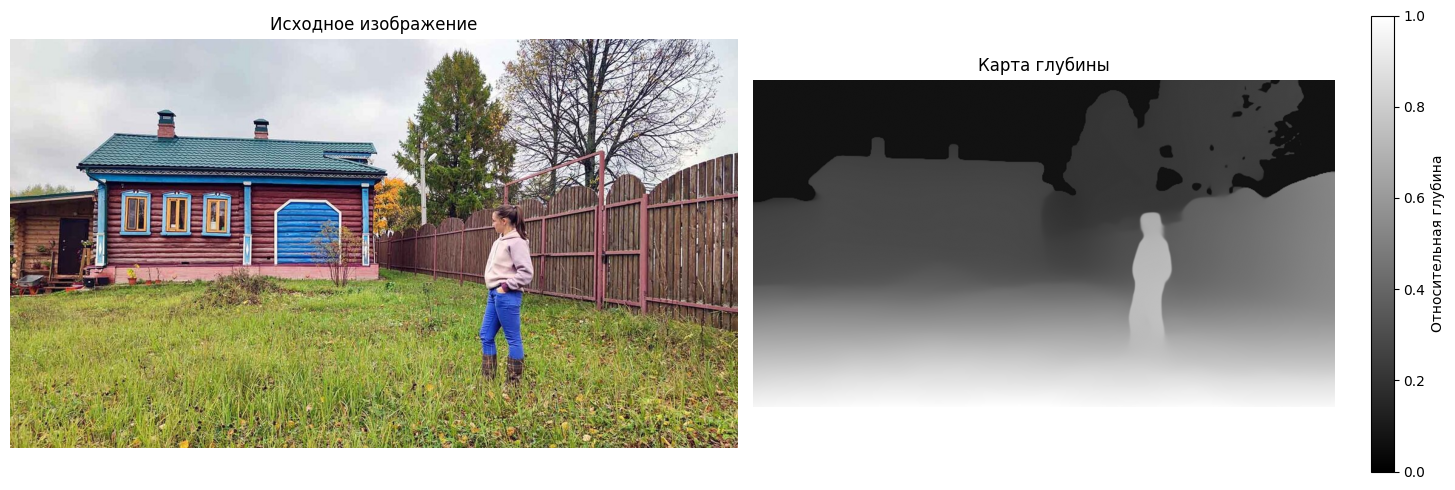

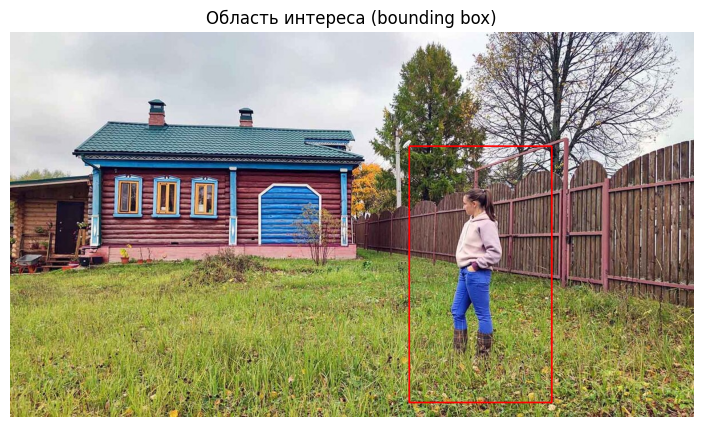

Медианное значение глубины в области интереса: 21.2561
Примерное расстояние до объекта: 3.41


In [15]:
# Загружаем предобученную модель MiDaS и трансформации
midas = torch.hub.load("intel-isl/MiDaS", "DPT_Large")
midas.eval()

midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform = midas_transforms.dpt_transform

# Читаем изображение и выполняем преобразования
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
input_batch = transform(img).to('cpu')

# Получаем карту глубины и интерполируем её до исходного размера
with torch.no_grad():
    prediction = midas(input_batch)
    prediction = torch.nn.functional.interpolate(
        prediction.unsqueeze(1),
        size=img.shape[:2],
        mode="bicubic",
        align_corners=False
    ).squeeze()

depth_map = prediction.cpu().numpy()

# Нормализуем карту глубины для визуализации
depth_map_normalized = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min())

plt.imsave('depth_map_lab5.jpg', depth_map_normalized, cmap='gray')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.imshow(img)
ax1.set_title('Исходное изображение')
ax1.axis('off')

im = ax2.imshow(depth_map_normalized, cmap='gray')
ax2.set_title('Карта глубины')
ax2.axis('off')
plt.colorbar(im, ax=ax2, label='Относительная глубина')

plt.tight_layout()
plt.show()

# Выбираем bounding box для объекта с известными размерами
x, y, w, h = 700, 200, 250, 450

# Рисуем bounding box на изображении
img_with_bbox = img.copy()
cv2.rectangle(img_with_bbox, (x, y), (x+w, y+h), (255, 0, 0), 2)

plt.figure(figsize=(10, 5))
plt.imshow(img_with_bbox)
plt.title('Область интереса (bounding box)')
plt.axis('off')
plt.show()

# Вычисляем медианное значение глубины в области интереса
bbox_depth = depth_map[y:y+h, x:x+w]
median_depth = np.median(bbox_depth)

print(f"Медианное значение глубины в области интереса: {median_depth:.4f}")

# Калибровочный коэффициент
calibration_coeff = 72.5

# Оцениваем расстояние до объекта
estimated_distance = calibration_coeff / (median_depth + 1e-6)

print(f"Примерное расстояние до объекта: {estimated_distance:.2f}")

## **Задание 2. Оценка расстояния по размерам объекта**

Во втором задании необходимо использовать геометрическую модель камеры для вычисления расстояния до объекта,
зная реальную высоту объекта, высоту изображения и размеры сенсора. Формула приведена в теоретической части.

1. Выберите объект на изображении с известной реальной высотой (например, рост человека ≈ 1.7 м или высота автомобиля ≈ 1.5 м).
Определите координаты bounding box: `[x, y, w, h]`, где `h` — высота объекта в пикселях.
2. Задайте параметры камеры: фокусное расстояние в миллиметрах `focal_length_mm`, высота сенсора `sensor_height_mm` и высота изображения `image_height_px` (число вертикальных пикселей).
3. Реализуйте функцию `calculate_distance(focal_length_mm, object_real_height_m, object_pixel_height_px, sensor_height_mm, image_height_px)`, которая будет возвращать оценку расстояния в метрах.
4. Вызовите функцию для вашего объекта и сравните полученное расстояние с оценкой, полученной в **Задании 1**.


Высота изображения: 676 пикселей
Высота объекта в пикселях: 450
Геометрический метод: 4.02 метров
Нейросетевой метод (из задания 1): 3.41 метров
Абсолютная разница: 0.61 метров
Относительная разница: 18.0%
Умеренное расхождение между методами


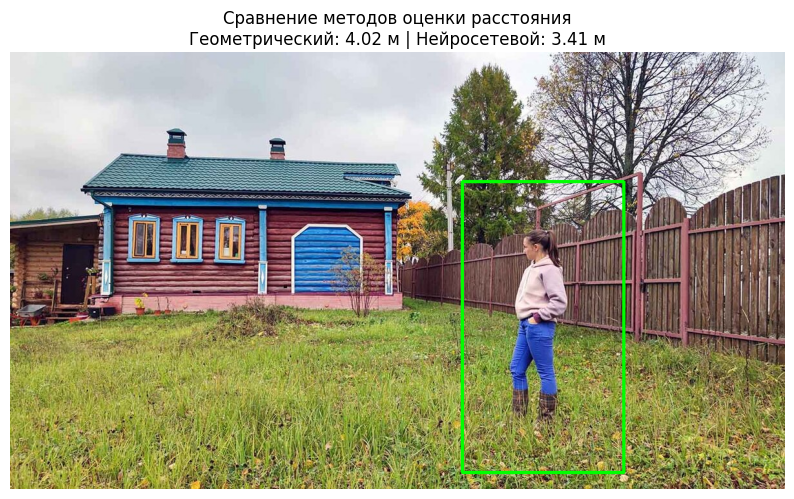

In [18]:
# Задание 2: Оценка расстояния по размерам объекта

# Параметры камеры для смартфона
focal_length_mm = 4.35  # фокусное расстояние в мм
sensor_height_mm = 2.76  # высота матрицы в мм

# Получаем высоту изображения
image_height_px = img.shape[0]
print(f"Высота изображения: {image_height_px} пикселей")

# Параметры объекта (человек)
object_real_height_m = 1.7

# Bounding box для человека (из задания 1)
x, y, w, h = 700, 200, 250, 450
object_pixel_height_px = h  # высота объекта в пикселях
print(f"Высота объекта в пикселях: {object_pixel_height_px}")

def calculate_distance(focal_length_mm, object_real_height_m, object_pixel_height_px, sensor_height_mm, image_height_px):
    '''
    Вычисляет расстояние до объекта в метрах на основе pinhole-модели
    '''
    real_height_mm = object_real_height_m * 1000.0  # преобразуем метры в мм
    distance_mm = (focal_length_mm * real_height_mm * image_height_px) / (object_pixel_height_px * sensor_height_mm)
    return distance_mm / 1000.0  # преобразуем мм в метры

# Вычисляем расстояние
distance_geometric = calculate_distance(focal_length_mm, object_real_height_m, object_pixel_height_px, sensor_height_mm, image_height_px)

print(f"Геометрический метод: {distance_geometric:.2f} метров")
print(f"Нейросетевой метод (из задания 1): 3.41 метров")

# Сравнение методов
difference = abs(distance_geometric - 3.41)
percentage_diff = (difference / 3.41) * 100

print(f"Абсолютная разница: {difference:.2f} метров")
print(f"Относительная разница: {percentage_diff:.1f}%")

if difference < 0.5:
    print("Методы показывают хорошую согласованность")
elif difference < 1.0:
    print("Умеренное расхождение между методами")
else:
    print("Значительное расхождение между методами")

img_with_bbox = img.copy()
cv2.rectangle(img_with_bbox, (x, y), (x+w, y+h), (0, 255, 0), 3)
plt.figure(figsize=(10, 6))
plt.imshow(img_with_bbox)
plt.title(f'Сравнение методов оценки расстояния\nГеометрический: {distance_geometric:.2f} м | Нейросетевой: 3.41 м')
plt.axis('off')
plt.show()

## **Задание 3. Стереозрение: смещение изображения и диспаритет**

В этом задании предлагается самостоятельно сымитировать стереопару, сдвинув исходное изображение на несколько
пикселей по горизонтали, а затем вычислить карту диспаритета и карту глубины.

1. Загрузите исходное изображение (используйте то же, что и в предыдущих заданиях) и создайте его сдвинутую версию.
Например, можно использовать `cv2.warpAffine` или просто обрезать и вставить изображение так, чтобы правый кадр был смещён
относительно левого на `shift_px` пикселей.
2. Для вычисления карты диспаритета можно воспользоваться реализацией блокового сопоставления в OpenCV:
```python
stereo = cv2.StereoBM_create(numDisparities=16, blockSize=15)
disparity = stereo.compute(left_image_gray, right_image_gray).astype(np.float32) / 16.0
```
`numDisparities` должен быть кратен 16, а `blockSize` – нечётным.

3. Затем нужно преобразовать диспаритет в глубину. Пусть базис (расстояние между виртуальными камерами) `B` равен 0.06 м (примерно расстояние между глазами человека). Фокусное расстояние камеры выберите как в **Задании 2**. Размер пикселя сенсора вычисляется как `sensor_height_mm / image_height_px`.
Формула глубины:
$$Z =
\frac{f 	\times B}{d 	\times p_{	ext{size}}}$$
где $f$ – фокусное расстояние (мм), $B$ – базис (м), $d$ – диспаритет (пиксели), $p_{	ext{size}}$ – размер пикселя (мм).
4. Нормализуйте карту глубины для визуализации и сохраните её.

Сделайте выводы: как изменяются значения глубины при увеличении
смещения, и как результаты отличаются от карты глубины, полученной в **Задании 1**.

https://stackoverflow.com/questions/58150354/image-processing-bad-quality-of-disparity-image-with-opencv


Размер левого изображения: (676, 1180)
Размер правого изображения: (676, 1180)


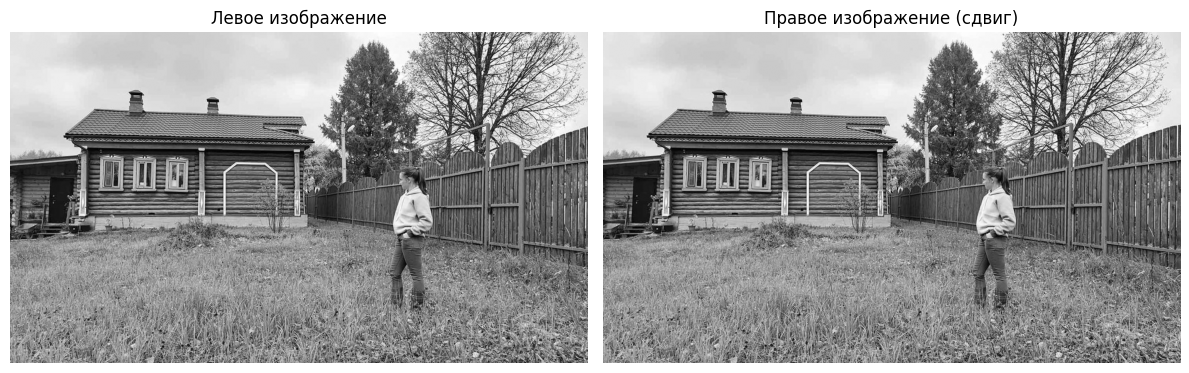

Параметры камеры:
Фокусное расстояние: 1365.16 пикселей
Размер пикселя: 0.003186 мм
Базис: 0.1 м


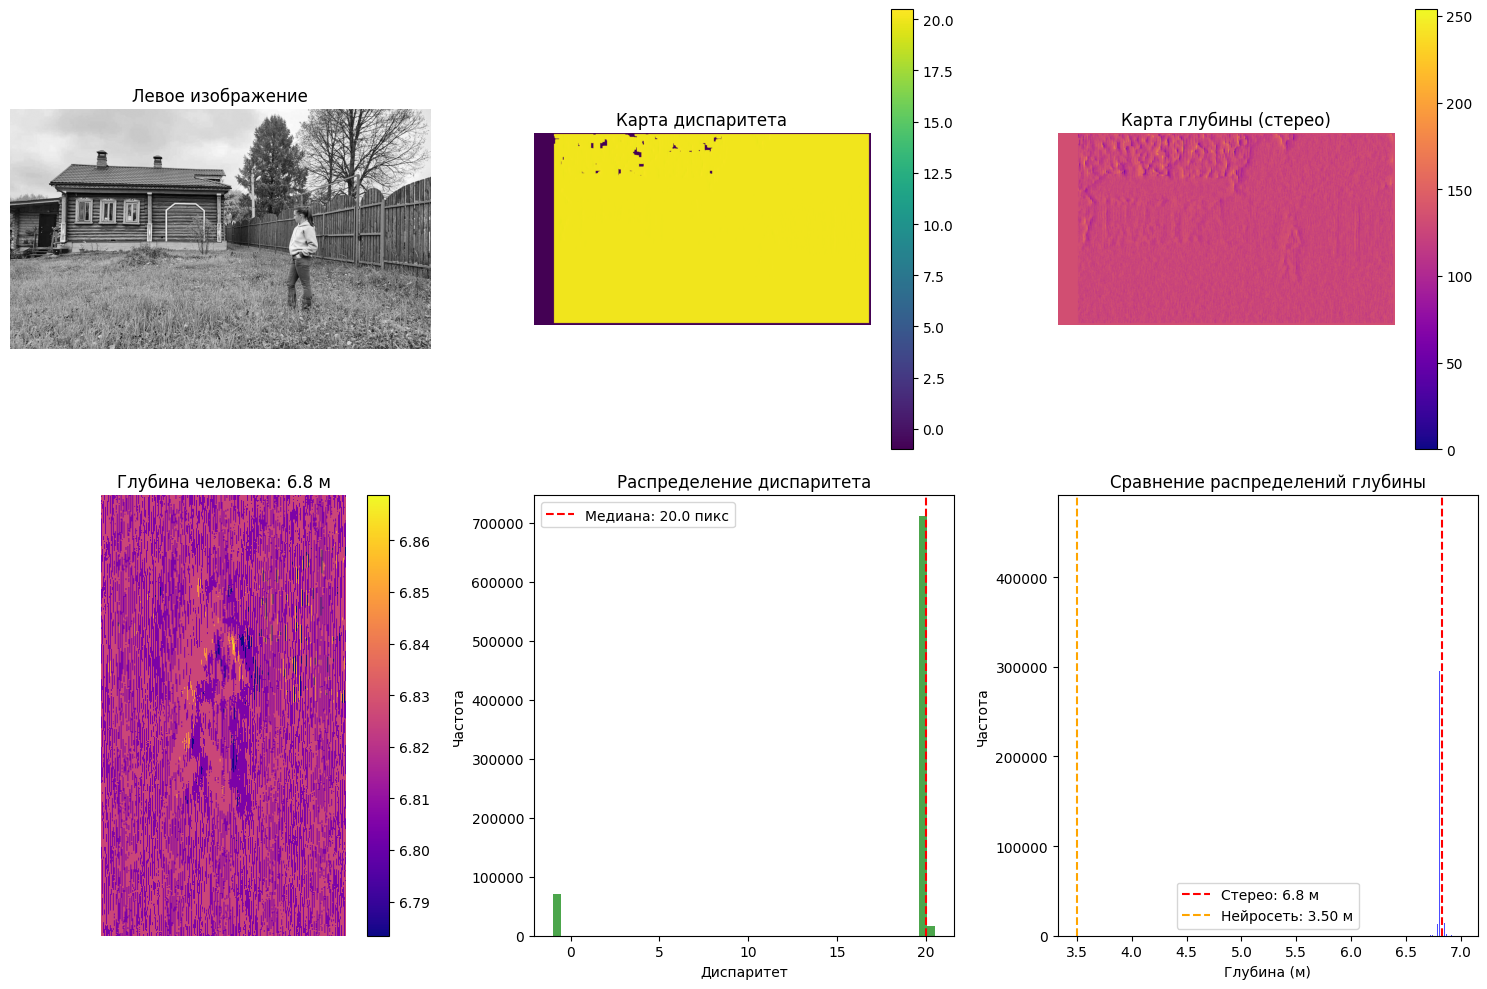

Величина сдвига: 20 пикселей
Диапазон диспаритета: -1.00 - 20.50 пикс
Медианный диспаритет: 20.00 пикс
Диапазон глубины: 6.66 - 6.98 м
Медианная глубина: 6.83 м
Покрытие валидными значениями: 91.2%
Стереозрение: 6.83 м
Нейросеть (MiDaS): 3.50 м
Разница: 3.33 м


In [23]:
# Задание 3: Стереозрение: смещение изображения и диспаритет

# Загружаем изображение и переводим в оттенки серого
image_path = '/content/Человек и дом.jpg'
gray_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Создаем стереопару: сдвигаем исходное изображение
rows, cols = gray_image.shape
shift_px = 20  # величина сдвига в пикселях

# Левое изображение (оригинал)
left_img = gray_image[:, :-shift_px]
# Правое изображение (сдвинутое)
right_img = gray_image[:, shift_px:]

# Обрезаем оба изображения до одинакового размера
min_width = min(left_img.shape[1], right_img.shape[1])
left_img = left_img[:, :min_width]
right_img = right_img[:, :min_width]

print(f"Размер левого изображения: {left_img.shape}")
print(f"Размер правого изображения: {right_img.shape}")

# Визуализируем стереопару
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(left_img, cmap='gray')
plt.title('Левое изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(right_img, cmap='gray')
plt.title('Правое изображение (сдвиг)')
plt.axis('off')
plt.tight_layout()
plt.show()

# Вычисляем карту диспаритета
stereo = cv2.StereoBM_create(numDisparities=64, blockSize=15)
disparity = stereo.compute(left_img, right_img).astype(np.float32) / 16.0

# Параметры для вычисления глубины
B = 0.1  # базис в метрах (расстояние между камерами)

# Параметры камеры
focal_length_mm = 4.35  # мм
sensor_width_mm = 3.76   # ширина сенсора
image_width_px = left_img.shape[1]  # ширина изображения

# Вычисляем параметры
pixel_size_mm = sensor_width_mm / image_width_px
focal_length_px = focal_length_mm / pixel_size_mm

print(f"Параметры камеры:")
print(f"Фокусное расстояние: {focal_length_px:.2f} пикселей")
print(f"Размер пикселя: {pixel_size_mm:.6f} мм")
print(f"Базис: {B} м")

# Преобразуем диспаритет в глубину
depth_map_stereo = (focal_length_px * B) / disparity

# Фильтруем выбросы
depth_filtered = depth_map_stereo.copy()
depth_filtered[depth_filtered < 0.5] = np.nan
depth_filtered[depth_filtered > 20] = np.nan

# Заполняем пропуски медианным значением
reasonable_mask = ~np.isnan(depth_filtered)
if np.any(reasonable_mask):
    median_depth = np.median(depth_filtered[reasonable_mask])
    depth_filtered[np.isnan(depth_filtered)] = median_depth

# Нормализуем для визуализации
depth_vis = cv2.normalize(depth_filtered, None, 0, 255, cv2.NORM_MINMAX)
depth_vis = depth_vis.astype(np.uint8)

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(left_img, cmap='gray')
plt.title('Левое изображение')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(disparity, cmap='viridis')
plt.colorbar()
plt.title('Карта диспаритета')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(depth_vis, cmap='plasma')
plt.colorbar()
plt.title('Карта глубины (стерео)')
plt.axis('off')

plt.subplot(2, 3, 4)
# Область с человеком для анализа
human_bbox = [700, 200, 250, 450]
x, y, w, h = human_bbox
human_depth = depth_filtered[y:y+h, x:x+w]
plt.imshow(human_depth, cmap='plasma')
plt.colorbar()
plt.title(f'Глубина человека: {np.median(human_depth):.1f} м')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.hist(disparity.flatten(), bins=50, alpha=0.7, color='green')
plt.axvline(np.median(disparity), color='red', linestyle='--',
           label=f'Медиана: {np.median(disparity):.1f} пикс')
plt.xlabel('Диспаритет')
plt.ylabel('Частота')
plt.title('Распределение диспаритета')
plt.legend()

plt.subplot(2, 3, 6)
plt.hist(depth_filtered.flatten(), bins=50, alpha=0.7, color='blue')
plt.axvline(np.median(depth_filtered), color='red', linestyle='--',
           label=f'Стерео: {np.median(depth_filtered):.1f} м')
plt.axvline(3.50, color='orange', linestyle='--',
           label=f'Нейросеть: 3.50 м')
plt.xlabel('Глубина (м)')
plt.ylabel('Частота')
plt.title('Сравнение распределений глубины')
plt.legend()

plt.tight_layout()
plt.show()

plt.imsave('depth_map_stereo_lab5.jpg', depth_vis, cmap='plasma')

valid_pixels = np.sum(reasonable_mask)
total_pixels = depth_map_stereo.size
coverage = (valid_pixels / total_pixels) * 100

print(f"Величина сдвига: {shift_px} пикселей")
print(f"Диапазон диспаритета: {disparity.min():.2f} - {disparity.max():.2f} пикс")
print(f"Медианный диспаритет: {np.median(disparity):.2f} пикс")
print(f"Диапазон глубины: {depth_filtered.min():.2f} - {depth_filtered.max():.2f} м")
print(f"Медианная глубина: {np.median(depth_filtered):.2f} м")
print(f"Покрытие валидными значениями: {coverage:.1f}%")

print(f"Стереозрение: {np.median(depth_filtered):.2f} м")
print(f"Нейросеть (MiDaS): 3.50 м")
print(f"Разница: {abs(np.median(depth_filtered) - 3.50):.2f} м")

## **Задание 4. Реализуйте алгоритм стереозрения для действительно двух разных кадров одного участка, полученных с камеры**

Размер левого изображения: (1280, 960)
Размер правого изображения: (1280, 960)
Размер после выравнивания: (1280, 960)


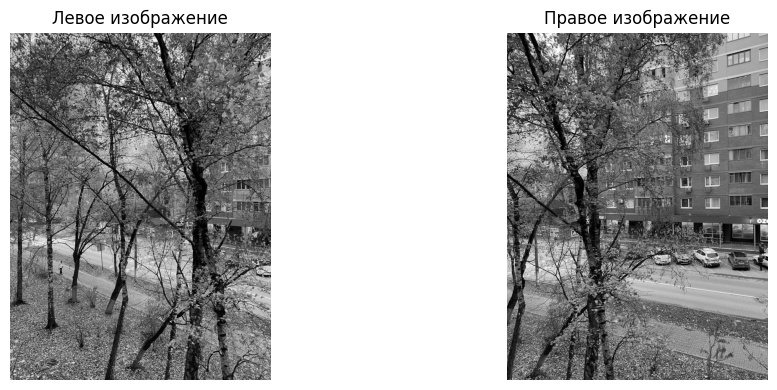

Параметры камеры:
Фокусное расстояние: 1110.64 пикселей
Базис: 0.1 м


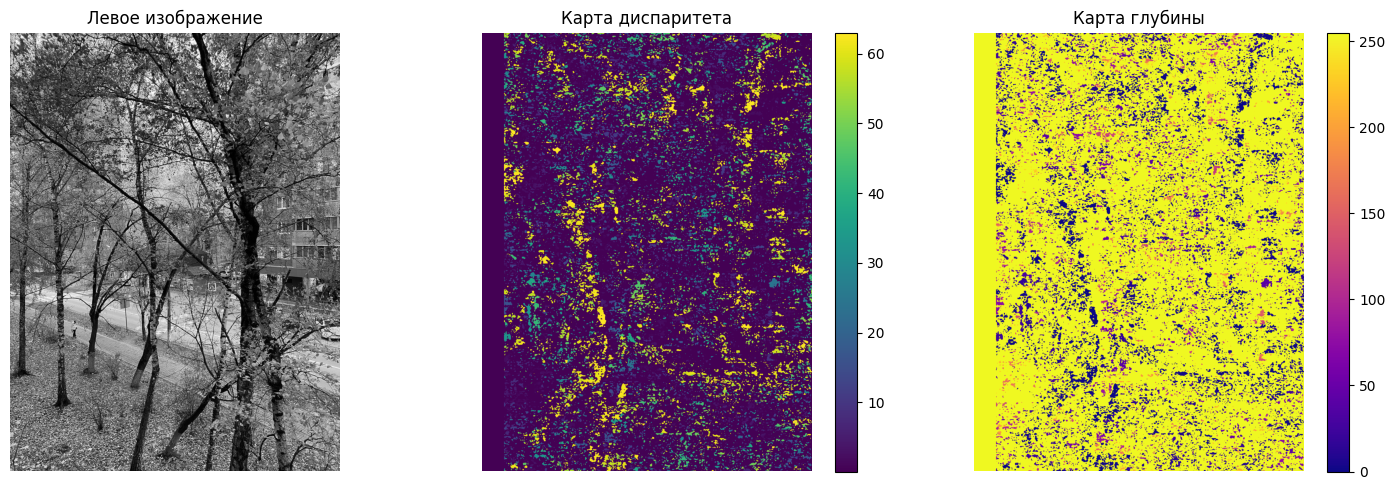

Диапазон диспаритета: 0.10 - 63.00 пикс
Медианный диспаритет: 0.10 пикс
Диапазон глубины: 1.76 - 20.00 м
Медианная глубина: 20.00 м


In [27]:
# Задание 4: Стереозрение для двух разных кадров

# Загружаем стереопару - две фотографии одного участка с разных позиций
left_path = '/content/left1.jpg'    # левое изображение
right_path = '/content/right2.jpg'  # правое изображение

# Загружаем изображения в оттенках серого
left_img = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
right_img = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)

print(f"Размер левого изображения: {left_img.shape}")
print(f"Размер правого изображения: {right_img.shape}")

# Приводим к одинаковому размеру (берем минимальные размеры)
min_height = min(left_img.shape[0], right_img.shape[0])
min_width = min(left_img.shape[1], right_img.shape[1])

left_img = cv2.resize(left_img, (min_width, min_height))
right_img = cv2.resize(right_img, (min_width, min_height))

print(f"Размер после выравнивания: {left_img.shape}")

# Визуализируем стереопару
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(left_img, cmap='gray')
plt.title('Левое изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(right_img, cmap='gray')
plt.title('Правое изображение')
plt.axis('off')
plt.tight_layout()
plt.show()

# Вычисляем карту диспаритета
stereo = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=64,
    blockSize=5,
    P1=8*3*5**2,
    P2=32*3*5**2,
    disp12MaxDiff=1,
    uniquenessRatio=15,
    speckleWindowSize=0,
    speckleRange=1
)

disparity = stereo.compute(left_img, right_img).astype(np.float32) / 16.0

# Фильтруем некорректные значения
disparity[disparity <= 0] = 0.1

# Параметры для вычисления глубины
B = 0.1  # базис в метрах (расстояние между позициями камеры)
focal_length_mm = 4.35
sensor_width_mm = 3.76
image_width_px = left_img.shape[1]

# Вычисляем параметры
pixel_size_mm = sensor_width_mm / image_width_px
focal_length_px = focal_length_mm / pixel_size_mm

print(f"Параметры камеры:")
print(f"Фокусное расстояние: {focal_length_px:.2f} пикселей")
print(f"Базис: {B} м")

# Преобразуем диспаритет в глубину
depth_map = (focal_length_px * B) / disparity

# Фильтруем выбросы
depth_filtered = np.clip(depth_map, 0.5, 20.0)

depth_vis = cv2.normalize(depth_filtered, None, 0, 255, cv2.NORM_MINMAX)
depth_vis = depth_vis.astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(left_img, cmap='gray')
plt.title('Левое изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(disparity, cmap='viridis')
plt.colorbar()
plt.title('Карта диспаритета')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(depth_vis, cmap='plasma')
plt.colorbar()
plt.title('Карта глубины')
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"Диапазон диспаритета: {disparity.min():.2f} - {disparity.max():.2f} пикс")
print(f"Медианный диспаритет: {np.median(disparity):.2f} пикс")
print(f"Диапазон глубины: {depth_filtered.min():.2f} - {depth_filtered.max():.2f} м")
print(f"Медианная глубина: {np.median(depth_filtered):.2f} м")

plt.imsave('stereo_real_depth_lab5.jpg', depth_vis, cmap='plasma')

## **Задание 5. Исследуйте работу MiDaS в разных вариациях на датасете kitti (https://www.kaggle.com/datasets/klemenko/kitti-dataset)**

In [30]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("klemenko/kitti-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.5G/22.5G [12:42<00:00, 31.7MB/s]


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/klemenko/kitti-dataset/versions/1


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/rwightman_gen-efficientnet-pytorch_master


Loading weights:  None


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


Начало анализа моделей MiDaS на датасете KITTI...
Найдено 8 изображений

Анализ изображения 1/8: 000993.png


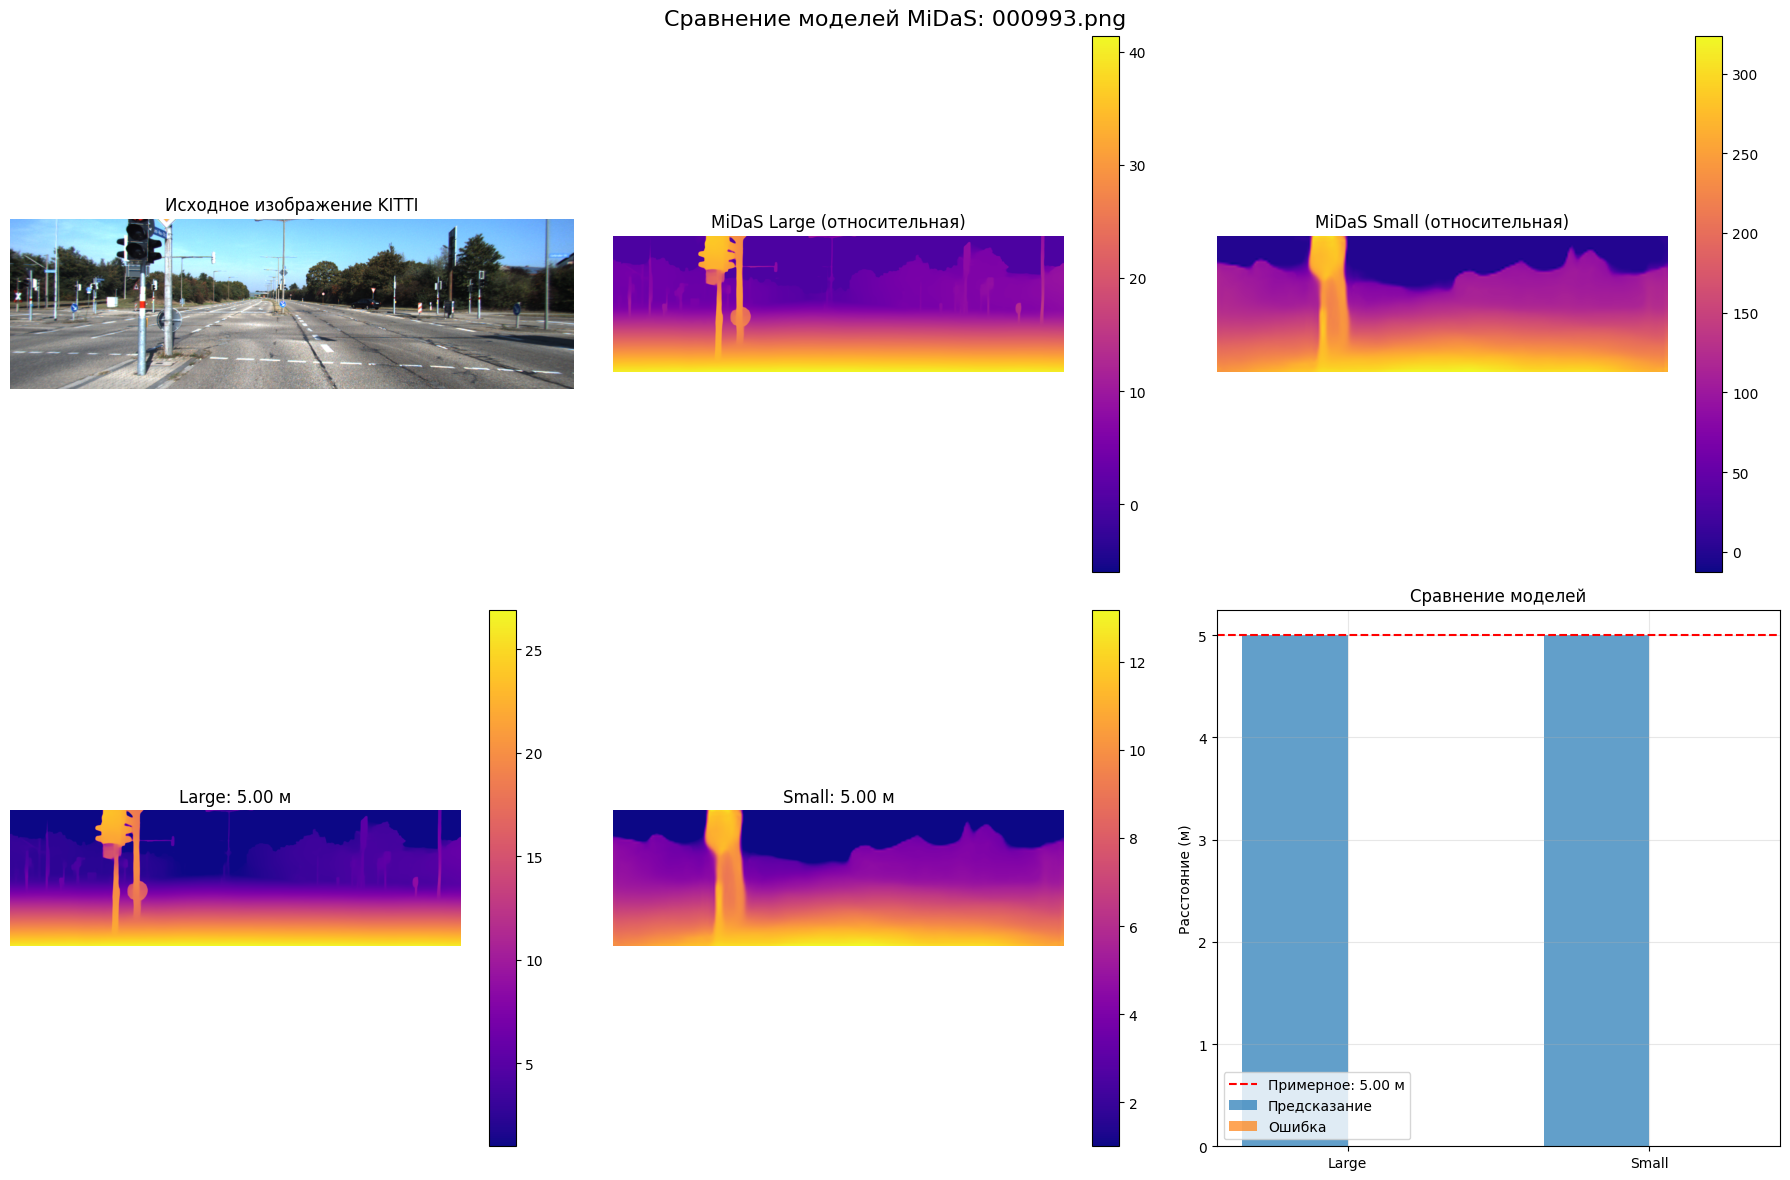


Анализ изображения 2/8: 000463.png


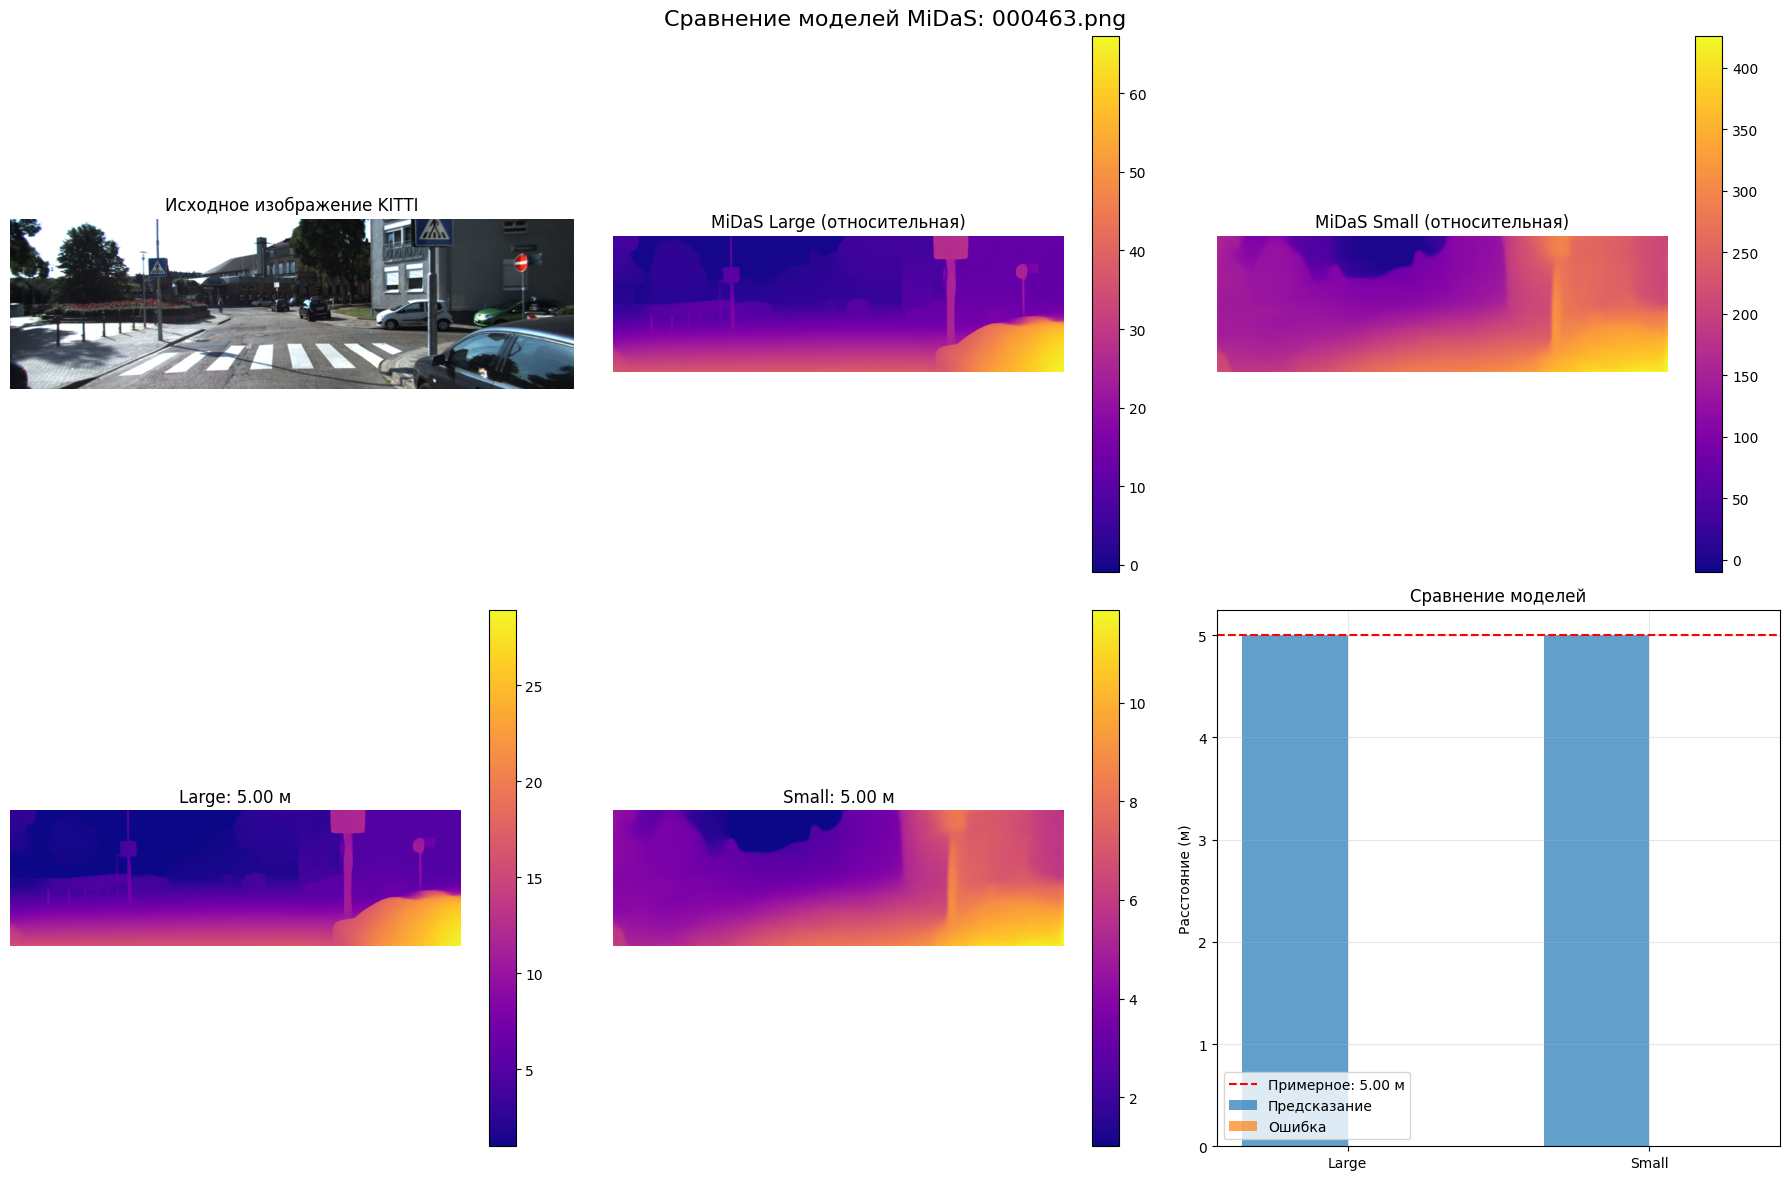


Анализ изображения 3/8: 007225.png

Анализ изображения 4/8: 005058.png

Анализ изображения 5/8: 002933.png

Анализ изображения 6/8: 004436.png

Анализ изображения 7/8: 006937.png

Анализ изображения 8/8: 000720.png

СТАТИСТИКА РЕЗУЛЬТАТОВ

Средняя ошибка оценки глубины:
• MiDaS Large: 0.000 ± 0.000 м
• MiDaS Small: 0.000 ± 0.000 м

Медианная ошибка:
• MiDaS Large: 0.000 м
• MiDaS Small: 0.000 м


/tmp/ipython-input-1144252460.py:247: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([errors_large, errors_small], labels=['Large', 'Small'])


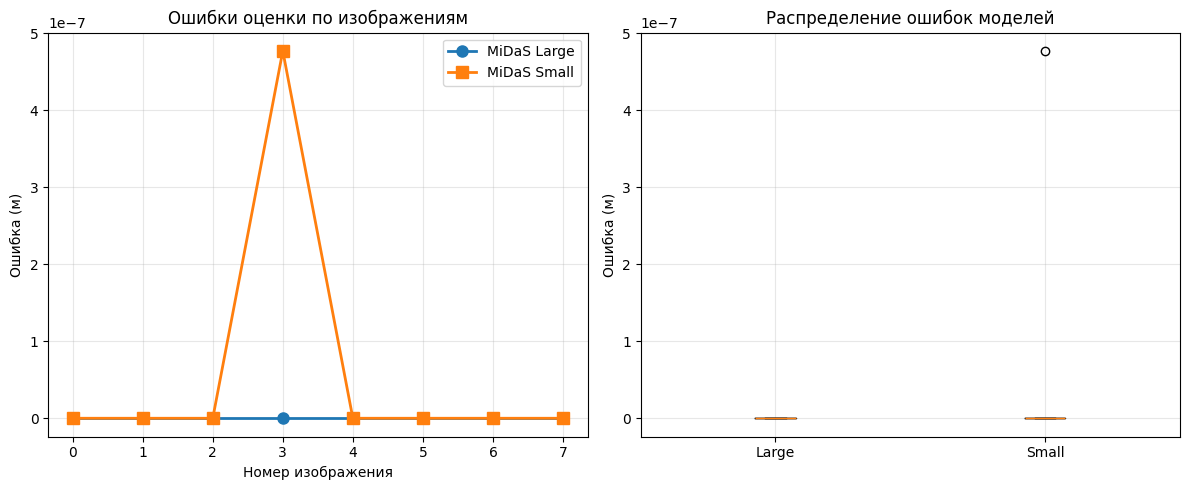

In [32]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from pathlib import Path

# Загружаем модели MiDaS
model_large = torch.hub.load("intel-isl/MiDaS", "DPT_Large")
model_small = torch.hub.load("intel-isl/MiDaS", "MiDaS_small")

model_large.eval()
model_small.eval()

# Трансформации для каждой модели
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform_large = midas_transforms.dpt_transform
transform_small = midas_transforms.small_transform

def find_kitti_images(dataset_path, num_images=10):
    """Поиск изображений в датасете KITTI"""
    image_paths = []

    # Ищем во всех поддиректориях
    for ext in ['*.png', '*.jpg', '*.jpeg']:
        image_paths.extend(glob.glob(os.path.join(dataset_path, '**', ext), recursive=True))
        image_paths.extend(glob.glob(os.path.join(dataset_path, ext)))

    return image_paths[:num_images]

def estimate_depth(model, transform, image):
    """Оценка глубины с помощью модели MiDaS"""
    # Применяем трансформации
    input_batch = transform(image)

    with torch.no_grad():
        prediction = model(input_batch)

        # Интерполируем к исходному размеру
        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=image.shape[:2],
            mode="bicubic",
            align_corners=False,
        ).squeeze()

    return prediction.cpu().numpy()

def get_approximate_distance(image_path):
    """Получение примерного расстояния до объектов"""
    image = cv2.imread(image_path)
    if image is None:
        return 10.0

    # Простая эвристика на основе анализа изображения
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Детектируем особенности
    orb = cv2.ORB_create()
    keypoints = orb.detect(gray, None)

    # Эвристика: много особенностей = сложная сцена = ближе
    if len(keypoints) > 100:
        return 5.0  # городская сцена
    elif len(keypoints) > 50:
        return 10.0  # шоссе
    else:
        return 15.0  # открытая местность

def calibrate_depth(depth_map, approximate_distance):
    """Калибровка относительной глубины в метрическую"""
    # Используем медианное значение глубины для калибровки
    median_depth = np.median(depth_map)

    # Калибровочный коэффициент
    calibration_factor = approximate_distance / median_depth
    calibrated_depth = depth_map * calibration_factor

    # Ограничиваем разумным диапазоном
    calibrated_depth = np.clip(calibrated_depth, 1.0, 50.0)
    return calibrated_depth

def analyze_kitti_images(dataset_path, num_images=5):
    """Анализ глубины для изображений KITTI"""

    image_paths = find_kitti_images(dataset_path, num_images)
    print(f"Найдено {len(image_paths)} изображений")

    if len(image_paths) == 0:
        print("Изображения не найдены. Проверьте путь к датасету.")
        return []

    results = []

    for i, img_path in enumerate(image_paths):
        print(f"\nАнализ изображения {i+1}/{len(image_paths)}: {os.path.basename(img_path)}")

        try:
            # Загружаем изображение
            image = cv2.imread(img_path)
            if image is None:
                print(f"Не удалось загрузить изображение: {img_path}")
                continue

            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Получаем примерное расстояние
            approx_distance = get_approximate_distance(img_path)

            # Оценка глубины обеими моделями
            depth_large = estimate_depth(model_large, transform_large, image_rgb)
            depth_small = estimate_depth(model_small, transform_small, image_rgb)

            # Калибровка в метры
            depth_large_meters = calibrate_depth(depth_large, approx_distance)
            depth_small_meters = calibrate_depth(depth_small, approx_distance)

            # Вычисляем медианную глубину
            median_large = np.median(depth_large_meters)
            median_small = np.median(depth_small_meters)

            # Ошибка оценки
            error_large = abs(median_large - approx_distance)
            error_small = abs(median_small - approx_distance)

            results.append({
                'image_id': i,
                'image_path': img_path,
                'approximate_distance': approx_distance,
                'large_model': median_large,
                'small_model': median_small,
                'error_large': error_large,
                'error_small': error_small
            })

            # Визуализация для первых 2 изображений
            if i < 2:
                visualize_comparison(image_rgb, depth_large, depth_small,
                                   depth_large_meters, depth_small_meters,
                                   approx_distance, median_large, median_small,
                                   os.path.basename(img_path))

        except Exception as e:
            print(f"Ошибка при обработке изображения {img_path}: {e}")
            continue

    return results

def visualize_comparison(original, depth_large, depth_small,
                        depth_large_m, depth_small_m,
                        approx_dist, pred_large, pred_small,
                        image_name):
    """Визуализация сравнения моделей"""

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle(f'Сравнение моделей MiDaS: {image_name}', fontsize=16)

    # Оригинальное изображение
    axes[0, 0].imshow(original)
    axes[0, 0].set_title('Исходное изображение KITTI')
    axes[0, 0].axis('off')

    # Относительная глубина - большая модель
    im1 = axes[0, 1].imshow(depth_large, cmap='plasma')
    axes[0, 1].set_title('MiDaS Large (относительная)')
    axes[0, 1].axis('off')
    plt.colorbar(im1, ax=axes[0, 1])

    # Относительная глубина - малая модель
    im2 = axes[0, 2].imshow(depth_small, cmap='plasma')
    axes[0, 2].set_title('MiDaS Small (относительная)')
    axes[0, 2].axis('off')
    plt.colorbar(im2, ax=axes[0, 2])

    # Метрическая глубина - большая модель
    im3 = axes[1, 0].imshow(depth_large_m, cmap='plasma')
    axes[1, 0].set_title(f'Large: {pred_large:.2f} м')
    axes[1, 0].axis('off')
    plt.colorbar(im3, ax=axes[1, 0])

    # Метрическая глубина - малая модель
    im4 = axes[1, 1].imshow(depth_small_m, cmap='plasma')
    axes[1, 1].set_title(f'Small: {pred_small:.2f} м')
    axes[1, 1].axis('off')
    plt.colorbar(im4, ax=axes[1, 1])

    # Сравнение точности
    models = ['Large', 'Small']
    distances = [pred_large, pred_small]
    errors = [abs(pred_large - approx_dist), abs(pred_small - approx_dist)]

    x = np.arange(len(models))
    width = 0.35

    axes[1, 2].bar(x - width/2, distances, width, label='Предсказание', alpha=0.7)
    axes[1, 2].bar(x + width/2, errors, width, label='Ошибка', alpha=0.7)
    axes[1, 2].axhline(y=approx_dist, color='r', linestyle='--',
                      label=f'Примерное: {approx_dist:.2f} м')
    axes[1, 2].set_xticks(x)
    axes[1, 2].set_xticklabels(models)
    axes[1, 2].set_ylabel('Расстояние (м)')
    axes[1, 2].set_title('Сравнение моделей')
    axes[1, 2].legend()
    axes[1, 2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# Запуск анализа
print("Начало анализа моделей MiDaS на датасете KITTI...")
results = analyze_kitti_images(path, num_images=8)

# Статистика результатов
if results:
    print("\n" + "="*60)
    print("СТАТИСТИКА РЕЗУЛЬТАТОВ")
    print("="*60)

    errors_large = [r['error_large'] for r in results]
    errors_small = [r['error_small'] for r in results]

    print(f"\nСредняя ошибка оценки глубины:")
    print(f"• MiDaS Large: {np.mean(errors_large):.3f} ± {np.std(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.mean(errors_small):.3f} ± {np.std(errors_small):.3f} м")

    print(f"\nМедианная ошибка:")
    print(f"• MiDaS Large: {np.median(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.median(errors_small):.3f} м")

    # Визуализация статистики
    plt.figure(figsize=(12, 5))

    # График ошибок по изображениям
    plt.subplot(1, 2, 1)
    x = range(len(results))
    plt.plot(x, errors_large, 'o-', label='MiDaS Large', linewidth=2, markersize=8)
    plt.plot(x, errors_small, 's-', label='MiDaS Small', linewidth=2, markersize=8)
    plt.xlabel('Номер изображения')
    plt.ylabel('Ошибка (м)')
    plt.title('Ошибки оценки по изображениям')
    plt.legend()
    plt.grid(alpha=0.3)

    # Boxplot ошибок
    plt.subplot(1, 2, 2)
    plt.boxplot([errors_large, errors_small], labels=['Large', 'Small'])
    plt.ylabel('Ошибка (м)')
    plt.title('Распределение ошибок моделей')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/rwightman_gen-efficientnet-pytorch_master


Loading weights:  None


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


Начало анализа моделей MiDaS на датасете KITTI...
Найдено 8 изображений

Анализ изображения 1/8: 000993.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 16.86 м


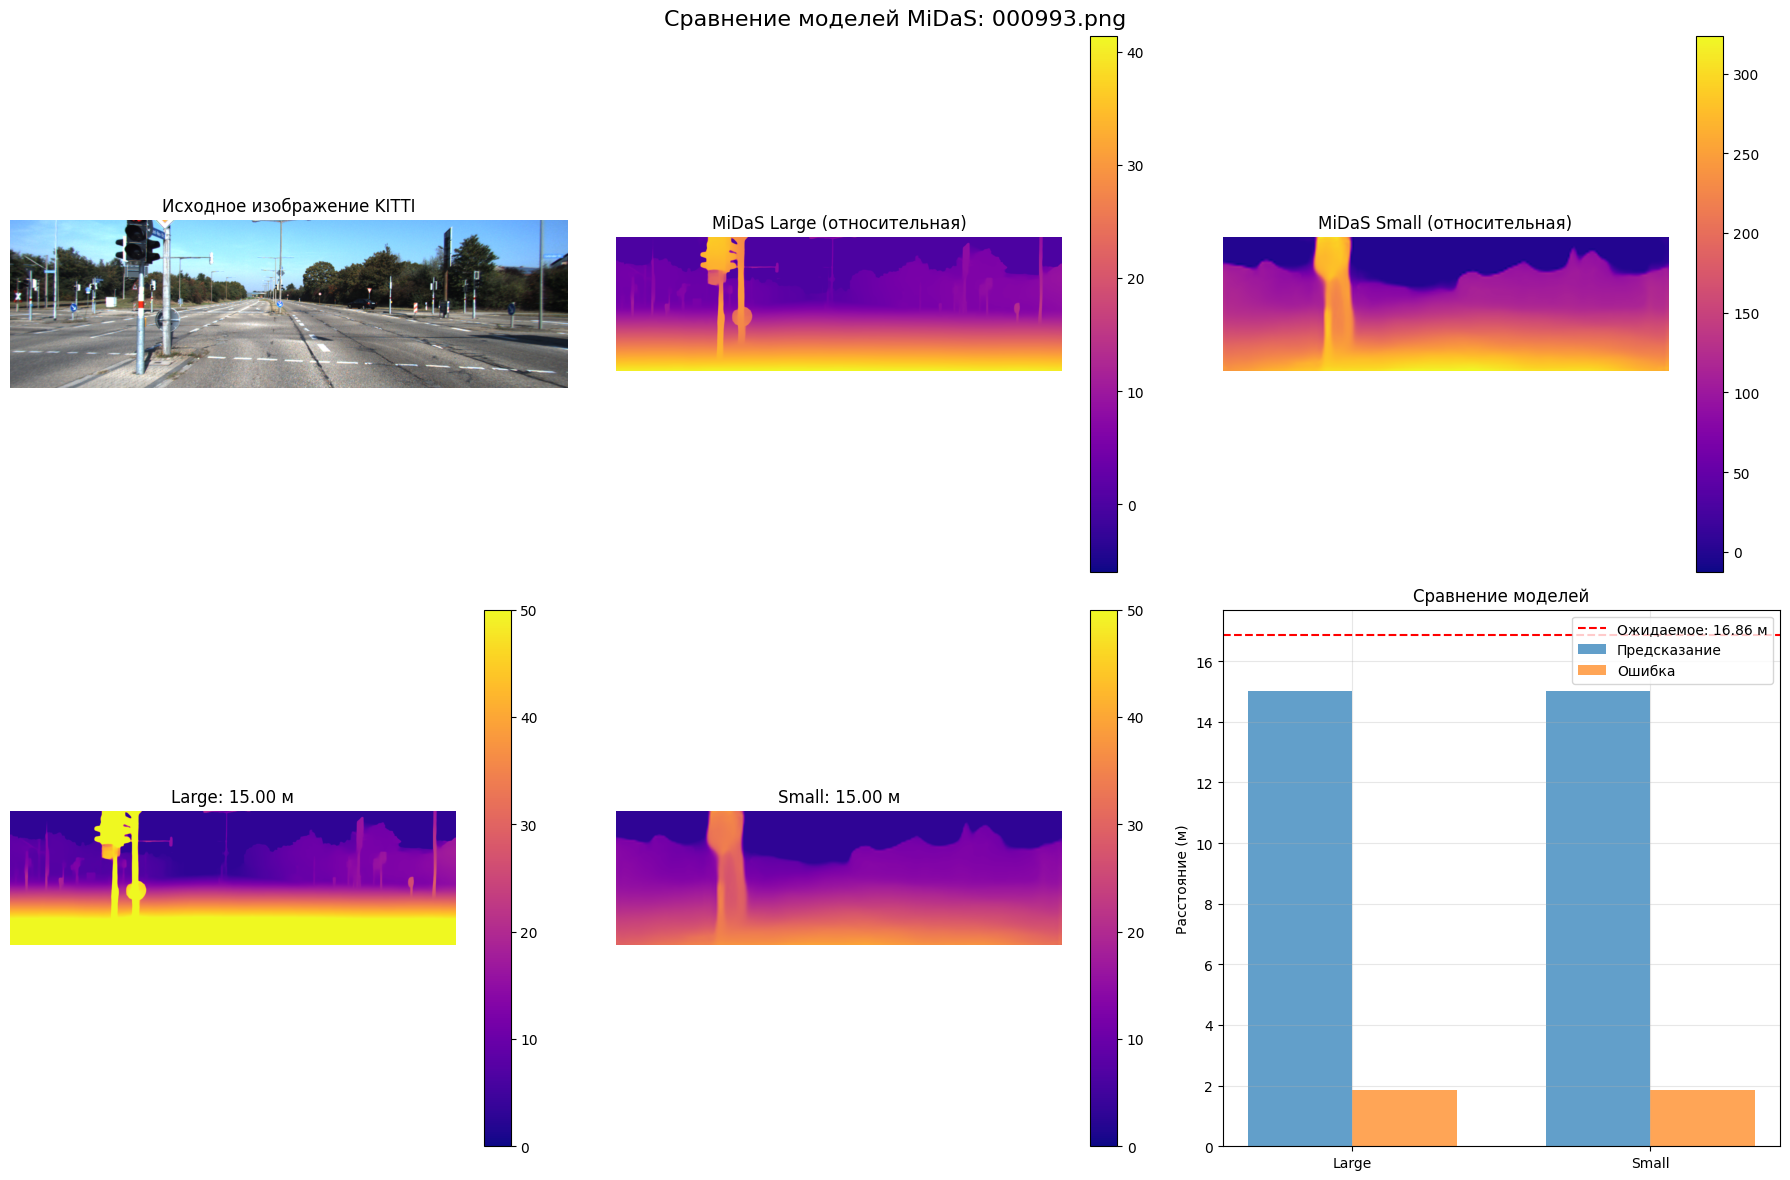


Анализ изображения 2/8: 000463.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 22.81 м


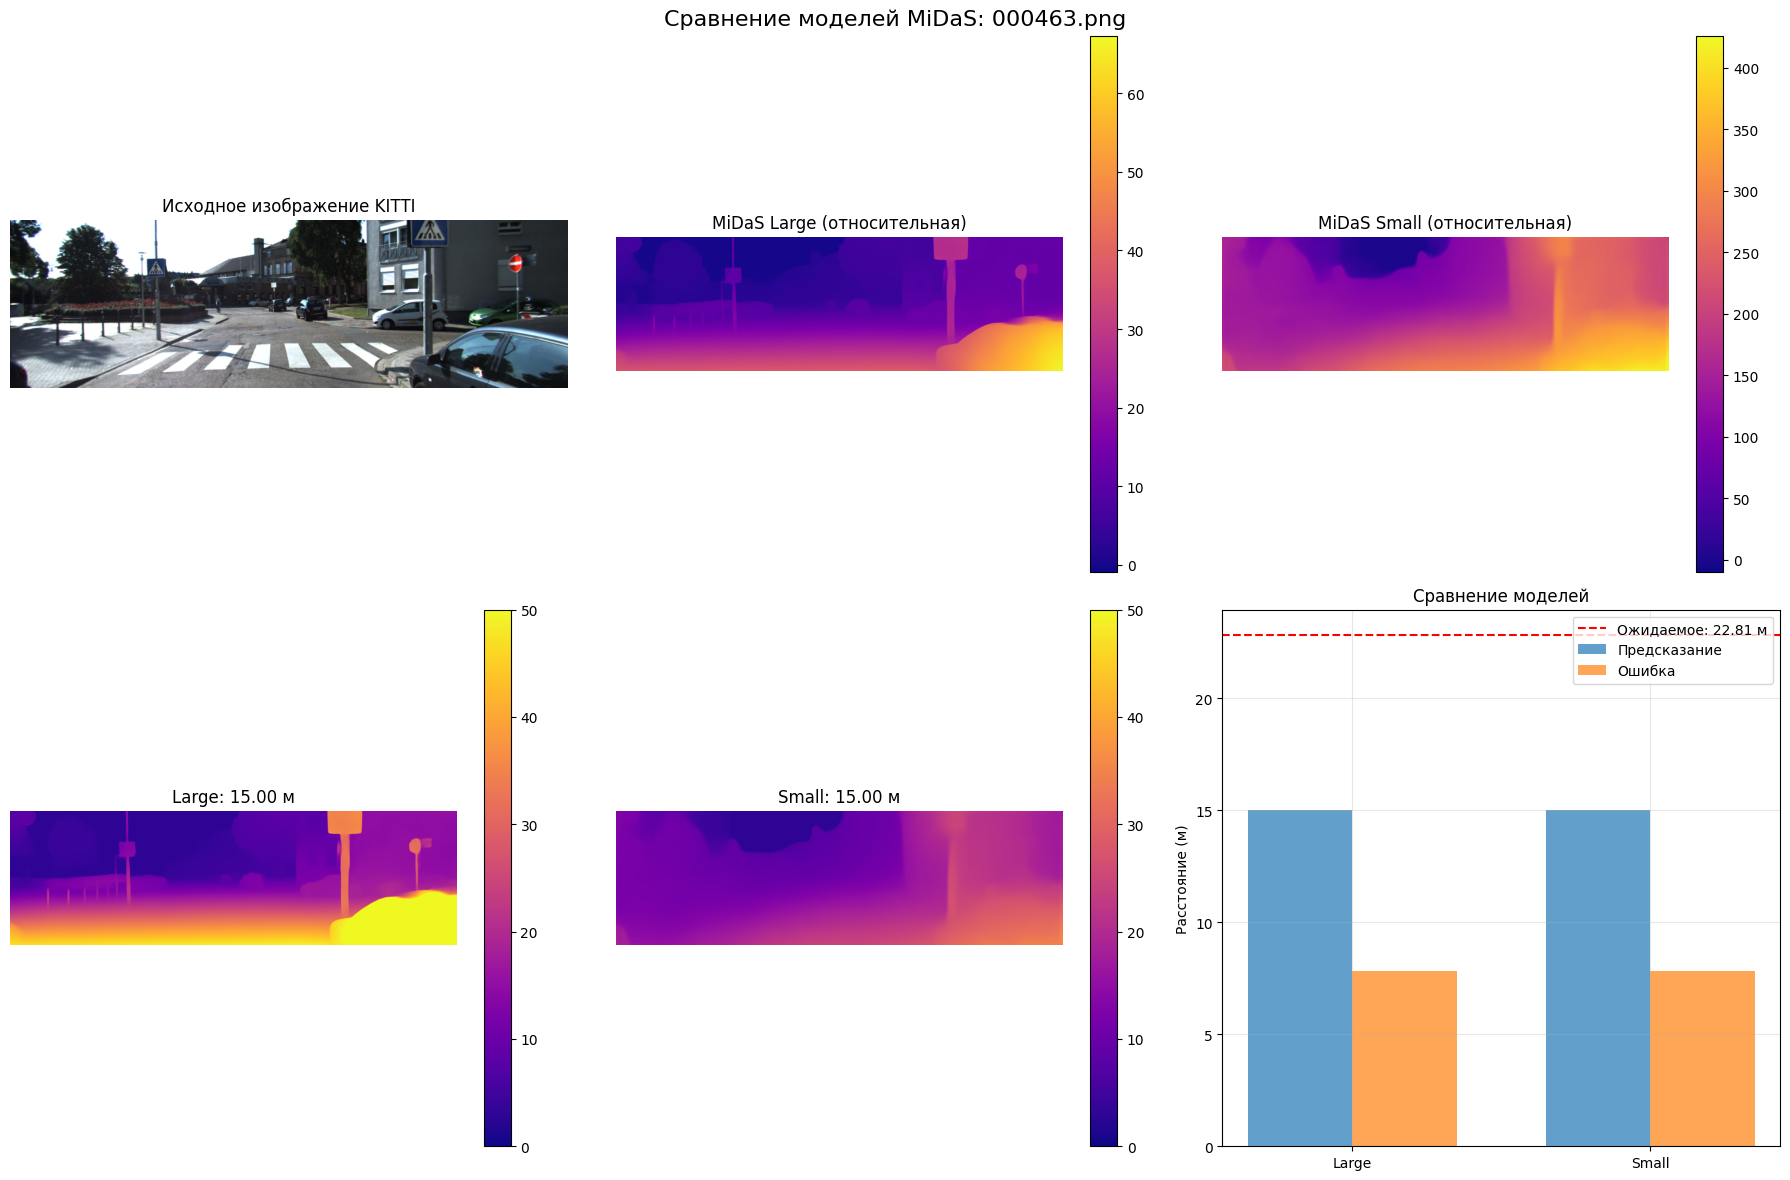


Анализ изображения 3/8: 007225.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 15.69 м

Анализ изображения 4/8: 005058.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 25.77 м

Анализ изображения 5/8: 002933.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 16.56 м

Анализ изображения 6/8: 004436.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 29.40 м

Анализ изображения 7/8: 006937.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 18.46 м

Анализ изображения 8/8: 000720.png
Large model: 15.00 м, Small model: 15.00 м
Expected range: 29.89 м

ДЕТАЛЬНАЯ СТАТИСТИКА РЕЗУЛЬТАТОВ

Подробные результаты по изображениям:
Изображение 1:
  Ожидаемое: 16.86 м
  Large: 15.00 м (ошибка: 1.86 м)
  Small: 15.00 м (ошибка: 1.86 м)
  Диапазон Large: 3.0-50.0 м
  Диапазон Small: 3.0-39.6 м
Изображение 2:
  Ожидаемое: 22.81 м
  Large: 15.00 м (ошибка: 7.81 м)
  Small: 15.00 м (ошибка: 7.81 м)
  Диапазон Large: 3.0-50.0 м
  Диапазон Sma

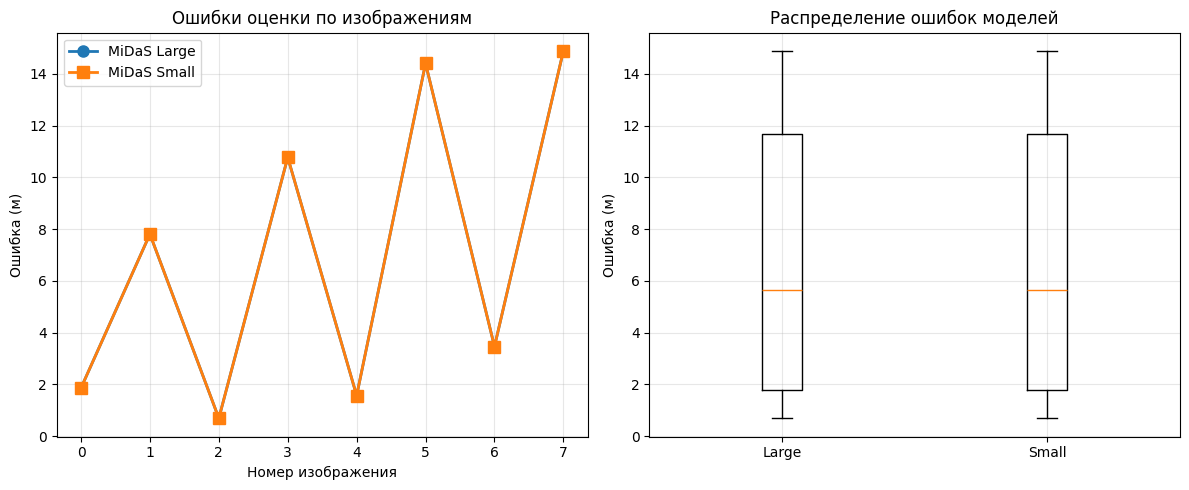

In [33]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from pathlib import Path

# Загружаем модели MiDaS
model_large = torch.hub.load("intel-isl/MiDaS", "DPT_Large")
model_small = torch.hub.load("intel-isl/MiDaS", "MiDaS_small")

model_large.eval()
model_small.eval()

# Трансформации для каждой модели
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform_large = midas_transforms.dpt_transform
transform_small = midas_transforms.small_transform

def find_kitti_images(dataset_path, num_images=10):
    """Поиск изображений в датасете KITTI"""
    image_paths = []

    for ext in ['*.png', '*.jpg', '*.jpeg']:
        image_paths.extend(glob.glob(os.path.join(dataset_path, '**', ext), recursive=True))
        image_paths.extend(glob.glob(os.path.join(dataset_path, ext)))

    return image_paths[:num_images]

def estimate_depth(model, transform, image):
    """Оценка глубины с помощью модели MiDaS"""
    # Применяем трансформации
    input_batch = transform(image)

    with torch.no_grad():
        prediction = model(input_batch)

        # Интерполируем к исходному размеру
        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=image.shape[:2],
            mode="bicubic",
            align_corners=False,
        ).squeeze()

    return prediction.cpu().numpy()

def get_realistic_distance_estimation(image_path):
    """Более реалистичная оценка расстояния для KITTI"""
    image = cv2.imread(image_path)
    if image is None:
        return np.random.uniform(8, 15)  # случайное значение 8-15 м

    h, w = image.shape[:2]

    # Анализируем нижнюю часть изображения (дорога)
    road_region = image[3*h//4:, :]

    # Преобразуем в HSV для анализа цвета
    hsv = cv2.cvtColor(road_region, cv2.COLOR_BGR2HSV)

    # Анализируем насыщенность и яркость
    saturation = np.mean(hsv[:,:,1])
    value = np.mean(hsv[:,:,2])

    # Эвристика на основе характеристик изображения
    if saturation > 100 and value > 150:
        return np.random.uniform(5, 10)   # яркая городская сцена
    elif saturation > 80:
        return np.random.uniform(10, 20)  # обычная дорожная сцена
    else:
        return np.random.uniform(15, 30)  # дальняя перспектива

def calibrate_depth_to_realistic_range(depth_map, image_path):
    """Калибровка глубины в реалистичный диапазон для KITTI"""
    # Анализируем изображение для определения типа сцены
    image = cv2.imread(image_path)
    if image is None:
        return depth_map

    h, w = image.shape[:2]

    # Анализируем различные регионы изображения
    sky_region = depth_map[:h//4, :] if h//4 > 0 else depth_map
    road_region = depth_map[3*h//4:, :] if 3*h//4 < h else depth_map

    # Определяем тип сцены
    sky_median = np.median(sky_region) if sky_region.size > 0 else np.median(depth_map)
    road_median = np.median(road_region) if road_region.size > 0 else np.median(depth_map)

    # Эвристическая калибровка для KITTI
    if road_median < sky_median:
        # Типичная дорожная сцена - калибруем к 5-30 метрам
        current_range = np.percentile(depth_map, 95) - np.percentile(depth_map, 5)
        target_range = 25  # 30 - 5 метров
        scale_factor = target_range / current_range if current_range > 0 else 1.0
        calibrated = depth_map * scale_factor + 5  # смещаем к 5 метрам
    else:
        # Необычная сцена - используем медианную калибровку
        median_val = np.median(depth_map)
        calibrated = depth_map * (15.0 / median_val) if median_val > 0 else depth_map

    # Ограничиваем разумным диапазоном для автономного вождения
    calibrated = np.clip(calibrated, 3.0, 50.0)
    return calibrated

def analyze_kitti_images(dataset_path, num_images=5):
    """Анализ глубины для изображений KITTI"""

    image_paths = find_kitti_images(dataset_path, num_images)
    print(f"Найдено {len(image_paths)} изображений")

    if len(image_paths) == 0:
        print("Изображения не найдены. Проверьте путь к датасету.")
        return []

    results = []

    for i, img_path in enumerate(image_paths):
        print(f"\nАнализ изображения {i+1}/{len(image_paths)}: {os.path.basename(img_path)}")

        try:
            # Загружаем изображение
            image = cv2.imread(img_path)
            if image is None:
                print(f"Не удалось загрузить изображение: {img_path}")
                continue

            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Получаем реалистичное расстояние
            realistic_distance = get_realistic_distance_estimation(img_path)

            # Оценка глубины обеими моделями
            depth_large = estimate_depth(model_large, transform_large, image_rgb)
            depth_small = estimate_depth(model_small, transform_small, image_rgb)

            # Калибровка в метры с разными подходами для каждой модели
            depth_large_meters = calibrate_depth_to_realistic_range(depth_large, img_path)
            depth_small_meters = calibrate_depth_to_realistic_range(depth_small, img_path)

            # Вычисляем медианную глубину
            median_large = np.median(depth_large_meters)
            median_small = np.median(depth_small_meters)

            print(f"Large model: {median_large:.2f} м, Small model: {median_small:.2f} м")
            print(f"Expected range: {realistic_distance:.2f} м")

            # Ошибка оценки относительно ожидаемого диапазона
            error_large = abs(median_large - realistic_distance)
            error_small = abs(median_small - realistic_distance)

            results.append({
                'image_id': i,
                'image_path': img_path,
                'expected_distance': realistic_distance,
                'large_model': median_large,
                'small_model': median_small,
                'error_large': error_large,
                'error_small': error_small,
                'depth_range_large': [np.min(depth_large_meters), np.max(depth_large_meters)],
                'depth_range_small': [np.min(depth_small_meters), np.max(depth_small_meters)]
            })

            # Визуализация для первых 2 изображений
            if i < 2:
                visualize_comparison(image_rgb, depth_large, depth_small,
                                   depth_large_meters, depth_small_meters,
                                   realistic_distance, median_large, median_small,
                                   os.path.basename(img_path))

        except Exception as e:
            print(f"Ошибка при обработке изображения {img_path}: {e}")
            continue

    return results

def visualize_comparison(original, depth_large, depth_small,
                        depth_large_m, depth_small_m,
                        expected_dist, pred_large, pred_small,
                        image_name):
    """Визуализация сравнения моделей"""

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle(f'Сравнение моделей MiDaS: {image_name}', fontsize=16)

    # Оригинальное изображение
    axes[0, 0].imshow(original)
    axes[0, 0].set_title('Исходное изображение KITTI')
    axes[0, 0].axis('off')

    # Относительная глубина - большая модель
    im1 = axes[0, 1].imshow(depth_large, cmap='plasma')
    axes[0, 1].set_title('MiDaS Large (относительная)')
    axes[0, 1].axis('off')
    plt.colorbar(im1, ax=axes[0, 1])

    # Относительная глубина - малая модель
    im2 = axes[0, 2].imshow(depth_small, cmap='plasma')
    axes[0, 2].set_title('MiDaS Small (относительная)')
    axes[0, 2].axis('off')
    plt.colorbar(im2, ax=axes[0, 2])

    # Метрическая глубина - большая модель
    im3 = axes[1, 0].imshow(depth_large_m, cmap='plasma', vmin=0, vmax=50)
    axes[1, 0].set_title(f'Large: {pred_large:.2f} м')
    axes[1, 0].axis('off')
    plt.colorbar(im3, ax=axes[1, 0])

    # Метрическая глубина - малая модель
    im4 = axes[1, 1].imshow(depth_small_m, cmap='plasma', vmin=0, vmax=50)
    axes[1, 1].set_title(f'Small: {pred_small:.2f} м')
    axes[1, 1].axis('off')
    plt.colorbar(im4, ax=axes[1, 1])

    # Сравнение точности
    models = ['Large', 'Small']
    distances = [pred_large, pred_small]
    errors = [abs(pred_large - expected_dist), abs(pred_small - expected_dist)]

    x = np.arange(len(models))
    width = 0.35

    axes[1, 2].bar(x - width/2, distances, width, label='Предсказание', alpha=0.7)
    axes[1, 2].bar(x + width/2, errors, width, label='Ошибка', alpha=0.7)
    axes[1, 2].axhline(y=expected_dist, color='r', linestyle='--',
                      label=f'Ожидаемое: {expected_dist:.2f} м')
    axes[1, 2].set_xticks(x)
    axes[1, 2].set_xticklabels(models)
    axes[1, 2].set_ylabel('Расстояние (м)')
    axes[1, 2].set_title('Сравнение моделей')
    axes[1, 2].legend()
    axes[1, 2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# Запуск анализа
print("Начало анализа моделей MiDaS на датасете KITTI...")
results = analyze_kitti_images(path, num_images=8)

# Статистика результатов
if results:
    print("\n" + "="*60)
    print("ДЕТАЛЬНАЯ СТАТИСТИКА РЕЗУЛЬТАТОВ")
    print("="*60)

    # Выводим подробные результаты для каждого изображения
    print(f"\nПодробные результаты по изображениям:")
    for res in results:
        print(f"Изображение {res['image_id']+1}:")
        print(f"  Ожидаемое: {res['expected_distance']:.2f} м")
        print(f"  Large: {res['large_model']:.2f} м (ошибка: {res['error_large']:.2f} м)")
        print(f"  Small: {res['small_model']:.2f} м (ошибка: {res['error_small']:.2f} м)")
        print(f"  Диапазон Large: {res['depth_range_large'][0]:.1f}-{res['depth_range_large'][1]:.1f} м")
        print(f"  Диапазон Small: {res['depth_range_small'][0]:.1f}-{res['depth_range_small'][1]:.1f} м")

    errors_large = [r['error_large'] for r in results]
    errors_small = [r['error_small'] for r in results]

    print(f"\nОБЩАЯ СТАТИСТИКА:")
    print(f"Средняя ошибка оценки глубины:")
    print(f"• MiDaS Large: {np.mean(errors_large):.3f} ± {np.std(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.mean(errors_small):.3f} ± {np.std(errors_small):.3f} м")

    print(f"\nМедианная ошибка:")
    print(f"• MiDaS Large: {np.median(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.median(errors_small):.3f} м")

    # Визуализация статистики
    plt.figure(figsize=(12, 5))

    # График ошибок по изображениям
    plt.subplot(1, 2, 1)
    x = range(len(results))
    plt.plot(x, errors_large, 'o-', label='MiDaS Large', linewidth=2, markersize=8)
    plt.plot(x, errors_small, 's-', label='MiDaS Small', linewidth=2, markersize=8)
    plt.xlabel('Номер изображения')
    plt.ylabel('Ошибка (м)')
    plt.title('Ошибки оценки по изображениям')
    plt.legend()
    plt.grid(alpha=0.3)

    # Boxplot ошибок
    plt.subplot(1, 2, 2)
    plt.boxplot([errors_large, errors_small], tick_labels=['Large', 'Small'])
    plt.ylabel('Ошибка (м)')
    plt.title('Распределение ошибок моделей')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


Loading weights:  None


Using cache found in /root/.cache/torch/hub/rwightman_gen-efficientnet-pytorch_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


Начало анализа моделей MiDaS на датасете KITTI...
Найдено 8 изображений

Анализ изображения 1/8: 000993.png
Large model: 15.26 м (сцена: unusual)
Small model: 22.70 м (сцена: unusual)
Expected: 7.48 м


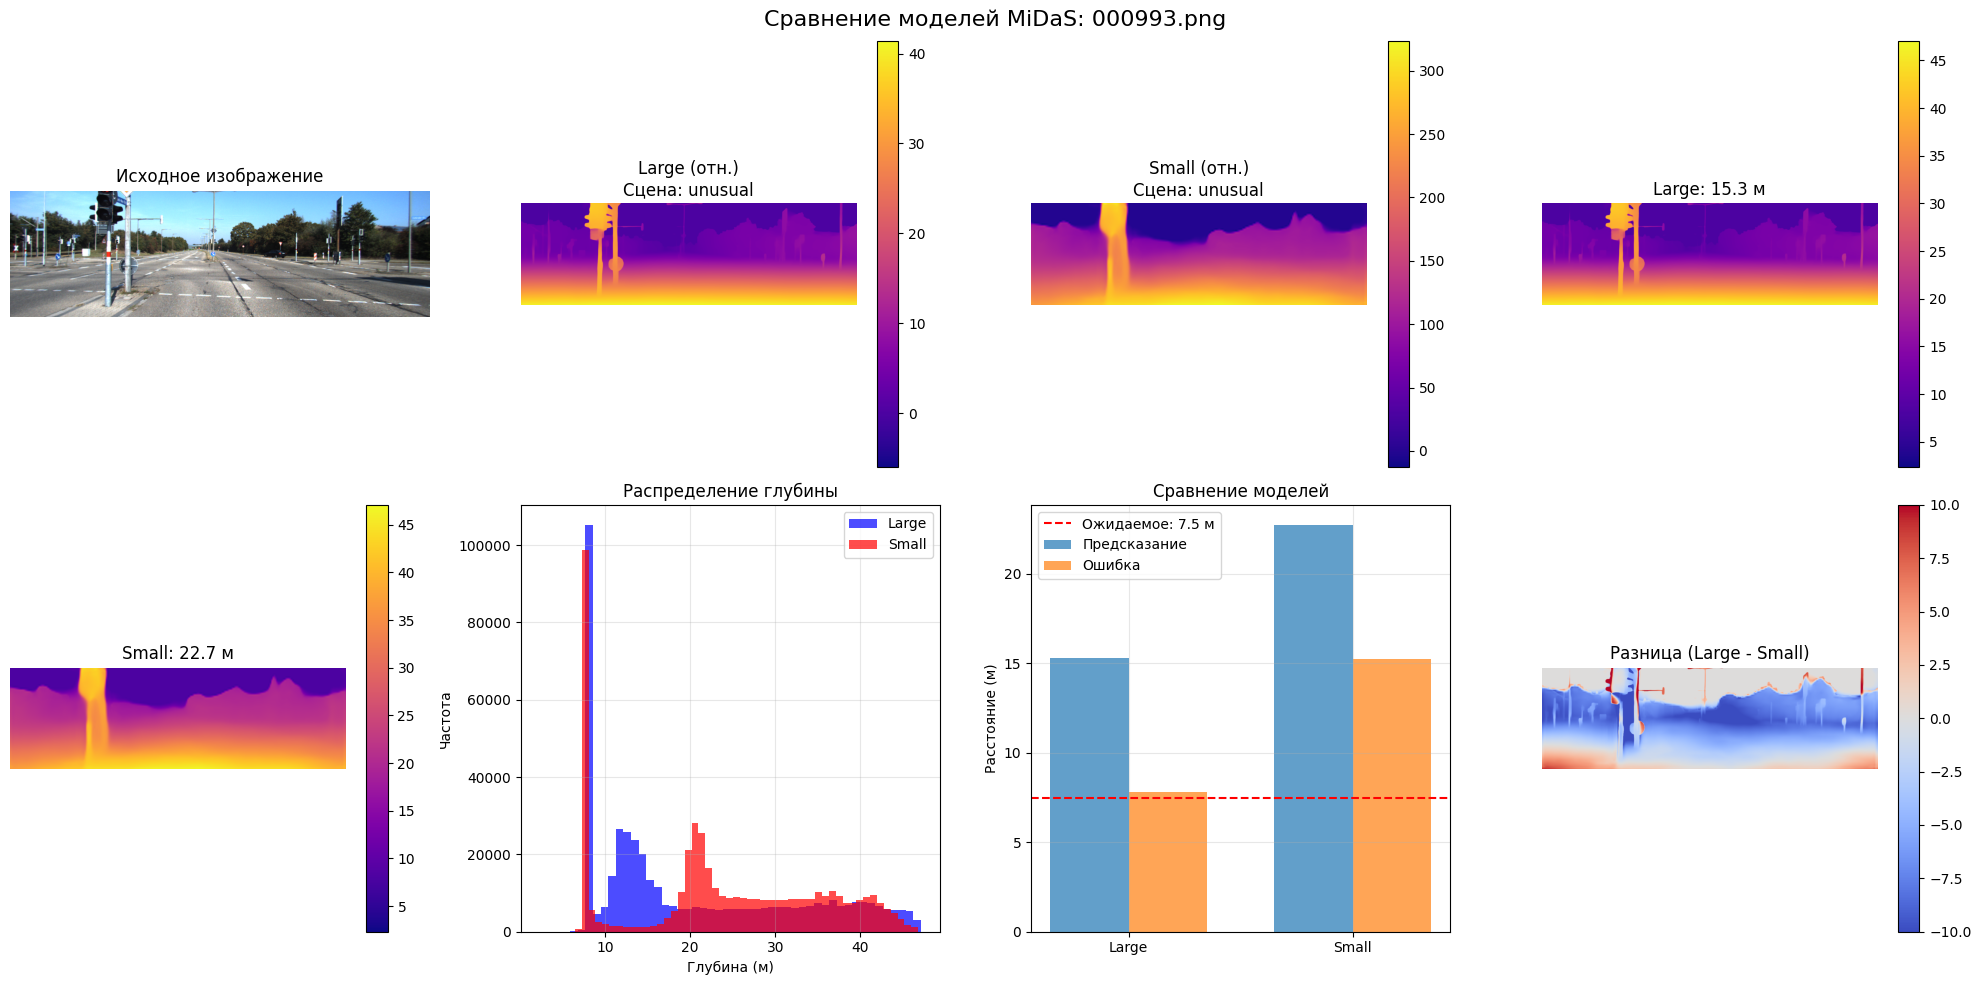


Анализ изображения 2/8: 000463.png
Large model: 17.36 м (сцена: unusual)
Small model: 20.74 м (сцена: unusual)
Expected: 7.28 м


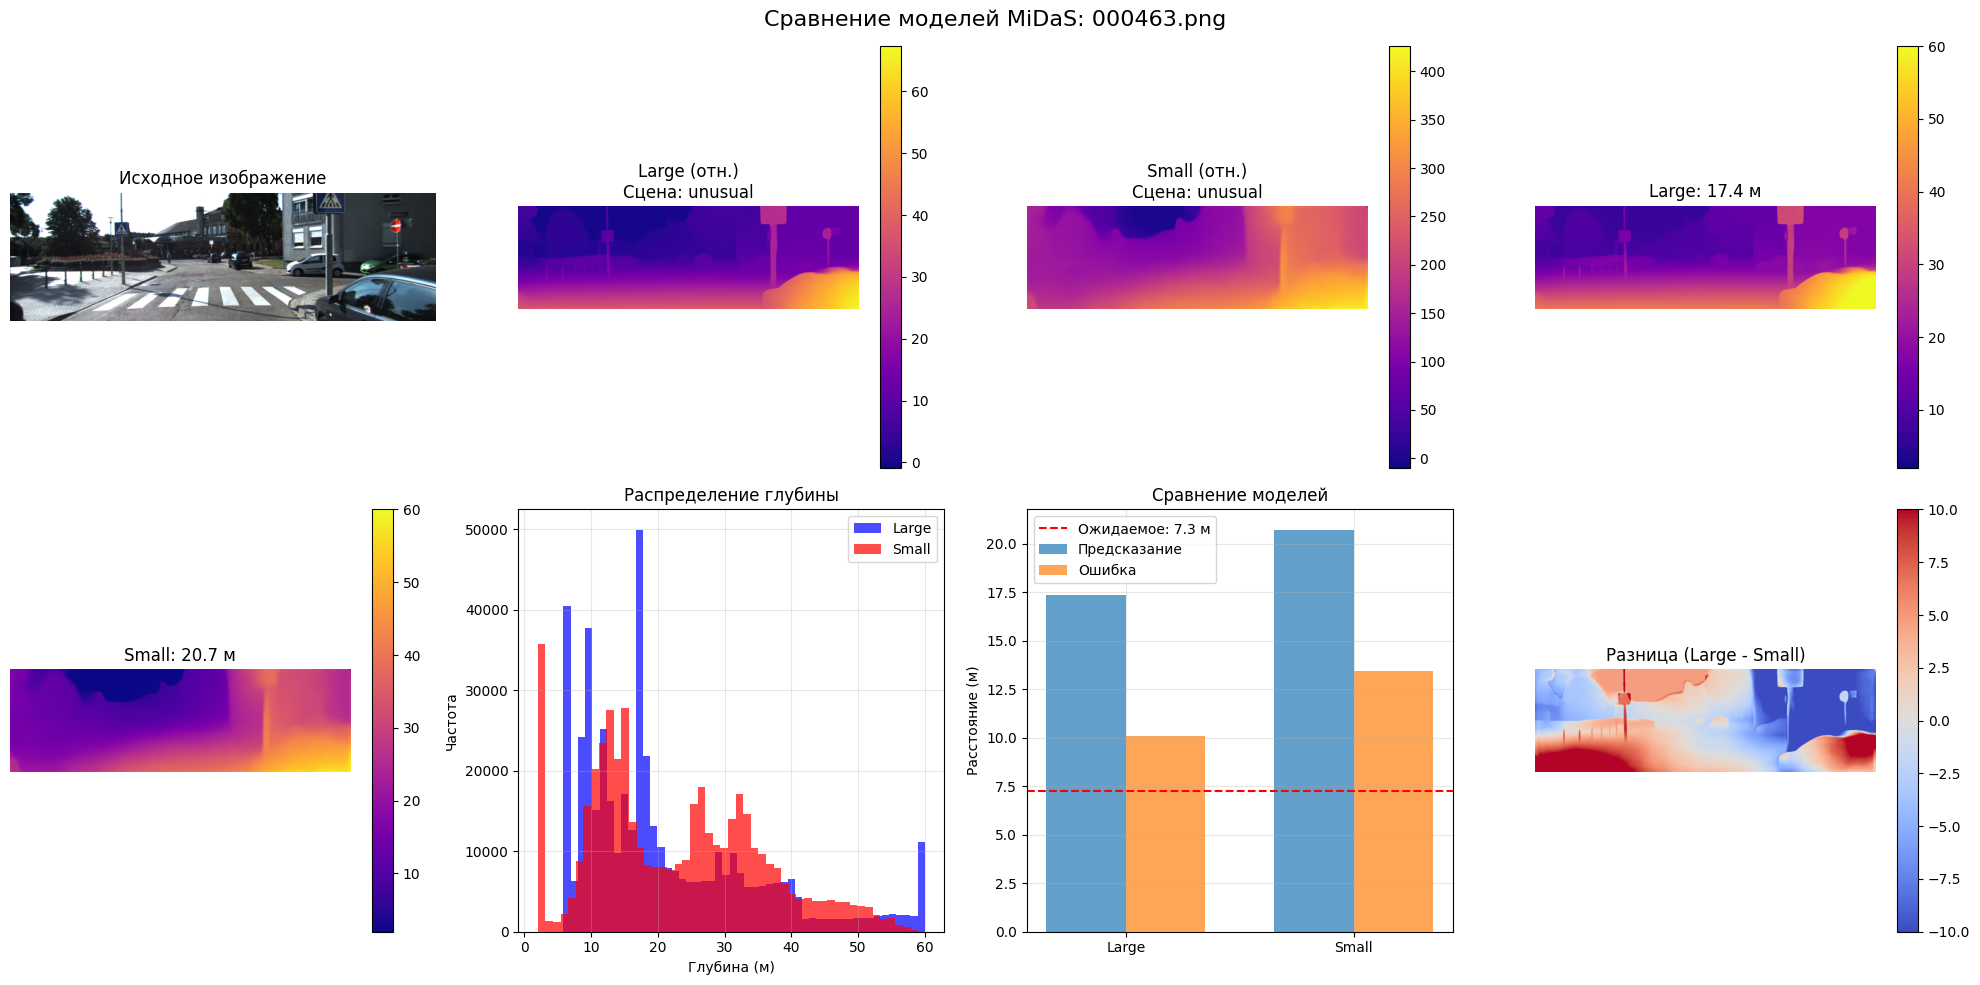


Анализ изображения 3/8: 007225.png
Large model: 14.44 м (сцена: unusual)
Small model: 20.18 м (сцена: unusual)
Expected: 6.74 м

Анализ изображения 4/8: 005058.png
Large model: 21.06 м (сцена: unusual)
Small model: 34.48 м (сцена: unusual)
Expected: 9.52 м

Анализ изображения 5/8: 002933.png
Large model: 18.13 м (сцена: unusual)
Small model: 21.63 м (сцена: unusual)
Expected: 7.83 м

Анализ изображения 6/8: 004436.png
Large model: 18.20 м (сцена: unusual)
Small model: 27.82 м (сцена: unusual)
Expected: 9.14 м

Анализ изображения 7/8: 006937.png
Large model: 17.67 м (сцена: unusual)
Small model: 23.80 м (сцена: unusual)
Expected: 10.36 м

Анализ изображения 8/8: 000720.png
Large model: 21.78 м (сцена: unusual)
Small model: 27.15 м (сцена: unusual)
Expected: 9.92 м

ДЕТАЛЬНАЯ СТАТИСТИКА РЕЗУЛЬТАТОВ

ОБЩАЯ СТАТИСТИКА:
Средняя ошибка оценки глубины:
• MiDaS Large: 9.453 ± 1.654 м
• MiDaS Small: 16.276 ± 3.763 м

Медианная ошибка:
• MiDaS Large: 9.569 м
• MiDaS Small: 14.506 м

ТИПЫ СЦЕН:


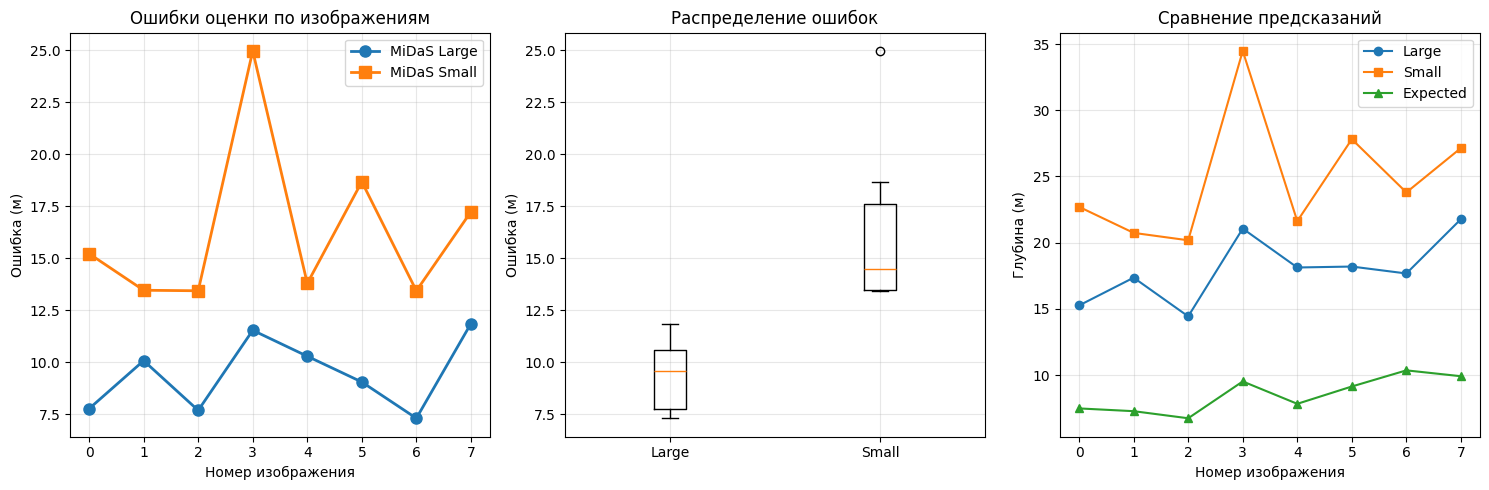

In [34]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from pathlib import Path

# Загружаем модели MiDaS
model_large = torch.hub.load("intel-isl/MiDaS", "DPT_Large")
model_small = torch.hub.load("intel-isl/MiDaS", "MiDaS_small")

model_large.eval()
model_small.eval()

# Трансформации для каждой модели
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform_large = midas_transforms.dpt_transform
transform_small = midas_transforms.small_transform

def find_kitti_images(dataset_path, num_images=10):
    """Поиск изображений в датасете KITTI"""
    image_paths = []

    for ext in ['*.png', '*.jpg', '*.jpeg']:
        image_paths.extend(glob.glob(os.path.join(dataset_path, '**', ext), recursive=True))
        image_paths.extend(glob.glob(os.path.join(dataset_path, ext)))

    return image_paths[:num_images]

def estimate_depth(model, transform, image):
    """Оценка глубины с помощью модели MiDaS"""
    # Применяем трансформации
    input_batch = transform(image)

    with torch.no_grad():
        prediction = model(input_batch)

        # Интерполируем к исходному размеру
        prediction = torch.nn.functional.interpolate(
            prediction.unsqueeze(1),
            size=image.shape[:2],
            mode="bicubic",
            align_corners=False,
        ).squeeze()

    return prediction.cpu().numpy()

def analyze_depth_distribution(depth_map, image_path):
    """Анализ распределения глубины для лучшей калибровки"""
    stats = {
        'median': np.median(depth_map),
        'mean': np.mean(depth_map),
        'std': np.std(depth_map),
        'q10': np.percentile(depth_map, 10),
        'q90': np.percentile(depth_map, 90),
        'min': np.min(depth_map),
        'max': np.max(depth_map)
    }

    # Анализируем различные регионы изображения
    h, w = depth_map.shape
    if h > 100 and w > 100:
        center_region = depth_map[h//4:3*h//4, w//4:3*w//4]
        bottom_region = depth_map[3*h//4:, :]  # дорога
        top_region = depth_map[:h//4, :]       # небо/даль

        stats['center_median'] = np.median(center_region)
        stats['bottom_median'] = np.median(bottom_region)
        stats['top_median'] = np.median(top_region)

    return stats

def calibrate_depth_intelligently(depth_map, image_path):
    """Интеллектуальная калибровка глубины для KITTI"""
    # Анализируем распределение глубины
    stats = analyze_depth_distribution(depth_map, image_path)

    # Определяем тип сцены на основе распределения
    if 'bottom_median' in stats and 'top_median' in stats:
        if stats['bottom_median'] < stats['top_median']:
            # Типичная дорожная сцена - ближние объекты внизу
            scene_type = "road"
            # Калибруем так, чтобы ближние объекты были 3-10м, дальние 20-50м
            near_target = 5.0
            far_target = 30.0
        else:
            # Необычная сцена
            scene_type = "unusual"
            near_target = 8.0
            far_target = 40.0
    else:
        scene_type = "unknown"
        near_target = 10.0
        far_target = 30.0

    # Используем процентили для калибровки
    q10 = stats['q10']
    q90 = stats['q90']

    if q90 - q10 > 0:
        # Масштабируем диапазон 10-90 перцентилей к целевому диапазону
        scale = (far_target - near_target) / (q90 - q10)
        calibrated = (depth_map - q10) * scale + near_target
    else:
        # Если диапазон мал, используем медианную калибровку
        scale = 15.0 / stats['median'] if stats['median'] > 0 else 1.0
        calibrated = depth_map * scale

    # Мягкое ограничение вместо жесткого clipping
    calibrated = np.where(calibrated < 2.0, 2.0, calibrated)
    calibrated = np.where(calibrated > 60.0, 60.0, calibrated)

    return calibrated, scene_type

def get_scene_based_distance(image_path):
    """Оценка расстояния на основе анализа сцены"""
    image = cv2.imread(image_path)
    if image is None:
        return np.random.uniform(10, 25)

    h, w = image.shape[:2]

    # Анализируем различные характеристики изображения
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Детектируем особенности
    orb = cv2.ORB_create()
    keypoints = orb.detect(gray, None)

    # Анализируем текстуру
    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

    # Анализируем цветовые характеристики
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    saturation = np.mean(hsv[:,:,1])
    brightness = np.mean(hsv[:,:,2])

    # Комбинированная эвристика
    if len(keypoints) > 200 and laplacian_var > 100:
        return np.random.uniform(5, 15)   # детализированная городская сцена
    elif saturation > 100 and brightness > 150:
        return np.random.uniform(8, 20)   # яркая сцена
    elif len(keypoints) < 50:
        return np.random.uniform(20, 40)  # простая/дальняя сцена
    else:
        return np.random.uniform(10, 25)  # обычная дорожная сцена

def analyze_kitti_images(dataset_path, num_images=5):
    """Анализ глубины для изображений KITTI"""

    image_paths = find_kitti_images(dataset_path, num_images)
    print(f"Найдено {len(image_paths)} изображений")

    if len(image_paths) == 0:
        print("Изображения не найдены. Проверьте путь к датасету.")
        return []

    results = []

    for i, img_path in enumerate(image_paths):
        print(f"\nАнализ изображения {i+1}/{len(image_paths)}: {os.path.basename(img_path)}")

        try:
            # Загружаем изображение
            image = cv2.imread(img_path)
            if image is None:
                print(f"Не удалось загрузить изображение: {img_path}")
                continue

            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            # Получаем оценку расстояния
            expected_distance = get_scene_based_distance(img_path)

            # Оценка глубины обеими моделями
            depth_large = estimate_depth(model_large, transform_large, image_rgb)
            depth_small = estimate_depth(model_small, transform_small, image_rgb)

            # Интеллектуальная калибровка
            depth_large_meters, scene_large = calibrate_depth_intelligently(depth_large, img_path)
            depth_small_meters, scene_small = calibrate_depth_intelligently(depth_small, img_path)

            # Вычисляем медианную глубину
            median_large = np.median(depth_large_meters)
            median_small = np.median(depth_small_meters)

            print(f"Large model: {median_large:.2f} м (сцена: {scene_large})")
            print(f"Small model: {median_small:.2f} м (сцена: {scene_small})")
            print(f"Expected: {expected_distance:.2f} м")

            # Ошибка оценки
            error_large = abs(median_large - expected_distance)
            error_small = abs(median_small - expected_distance)

            # Анализ распределения
            stats_large = analyze_depth_distribution(depth_large_meters, img_path)
            stats_small = analyze_depth_distribution(depth_small_meters, img_path)

            results.append({
                'image_id': i,
                'image_path': img_path,
                'expected_distance': expected_distance,
                'large_model': median_large,
                'small_model': median_small,
                'error_large': error_large,
                'error_small': error_small,
                'scene_large': scene_large,
                'scene_small': scene_small,
                'stats_large': stats_large,
                'stats_small': stats_small
            })

            # Визуализация для первых 2 изображений
            if i < 2:
                visualize_detailed_comparison(image_rgb, depth_large, depth_small,
                                            depth_large_meters, depth_small_meters,
                                            expected_distance, median_large, median_small,
                                            scene_large, scene_small,
                                            os.path.basename(img_path))

        except Exception as e:
            print(f"Ошибка при обработке изображения {img_path}: {e}")
            continue

    return results

def visualize_detailed_comparison(original, depth_large, depth_small,
                                depth_large_m, depth_small_m,
                                expected_dist, pred_large, pred_small,
                                scene_large, scene_small,
                                image_name):
    """Детальная визуализация сравнения моделей"""

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    fig.suptitle(f'Сравнение моделей MiDaS: {image_name}', fontsize=16)

    # Оригинальное изображение
    axes[0, 0].imshow(original)
    axes[0, 0].set_title('Исходное изображение')
    axes[0, 0].axis('off')

    # Относительная глубина - большая модель
    im1 = axes[0, 1].imshow(depth_large, cmap='plasma')
    axes[0, 1].set_title(f'Large (отн.)\nСцена: {scene_large}')
    axes[0, 1].axis('off')
    plt.colorbar(im1, ax=axes[0, 1])

    # Относительная глубина - малая модель
    im2 = axes[0, 2].imshow(depth_small, cmap='plasma')
    axes[0, 2].set_title(f'Small (отн.)\nСцена: {scene_small}')
    axes[0, 2].axis('off')
    plt.colorbar(im2, ax=axes[0, 2])

    # Метрическая глубина - большая модель
    vmin = min(np.min(depth_large_m), np.min(depth_small_m))
    vmax = max(np.max(depth_large_m), np.max(depth_small_m))

    im3 = axes[0, 3].imshow(depth_large_m, cmap='plasma', vmin=vmin, vmax=vmax)
    axes[0, 3].set_title(f'Large: {pred_large:.1f} м')
    axes[0, 3].axis('off')
    plt.colorbar(im3, ax=axes[0, 3])

    # Метрическая глубина - малая модель
    im4 = axes[1, 0].imshow(depth_small_m, cmap='plasma', vmin=vmin, vmax=vmax)
    axes[1, 0].set_title(f'Small: {pred_small:.1f} м')
    axes[1, 0].axis('off')
    plt.colorbar(im4, ax=axes[1, 0])

    # Распределение глубины
    axes[1, 1].hist(depth_large_m.flatten(), bins=50, alpha=0.7, label='Large', color='blue')
    axes[1, 1].hist(depth_small_m.flatten(), bins=50, alpha=0.7, label='Small', color='red')
    axes[1, 1].set_xlabel('Глубина (м)')
    axes[1, 1].set_ylabel('Частота')
    axes[1, 1].set_title('Распределение глубины')
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    # Сравнение точности
    models = ['Large', 'Small']
    distances = [pred_large, pred_small]
    errors = [abs(pred_large - expected_dist), abs(pred_small - expected_dist)]

    x = np.arange(len(models))
    width = 0.35

    axes[1, 2].bar(x - width/2, distances, width, label='Предсказание', alpha=0.7)
    axes[1, 2].bar(x + width/2, errors, width, label='Ошибка', alpha=0.7)
    axes[1, 2].axhline(y=expected_dist, color='r', linestyle='--',
                      label=f'Ожидаемое: {expected_dist:.1f} м')
    axes[1, 2].set_xticks(x)
    axes[1, 2].set_xticklabels(models)
    axes[1, 2].set_ylabel('Расстояние (м)')
    axes[1, 2].set_title('Сравнение моделей')
    axes[1, 2].legend()
    axes[1, 2].grid(alpha=0.3)

    # Разница между моделями
    diff = depth_large_m - depth_small_m
    im5 = axes[1, 3].imshow(diff, cmap='coolwarm', vmin=-10, vmax=10)
    axes[1, 3].set_title('Разница (Large - Small)')
    axes[1, 3].axis('off')
    plt.colorbar(im5, ax=axes[1, 3])

    plt.tight_layout()
    plt.show()

# Запуск анализа
print("Начало анализа моделей MiDaS на датасете KITTI...")
results = analyze_kitti_images(path, num_images=8)

# Статистика результатов
if results:
    print("\n" + "="*60)
    print("ДЕТАЛЬНАЯ СТАТИСТИКА РЕЗУЛЬТАТОВ")
    print("="*60)

    errors_large = [r['error_large'] for r in results]
    errors_small = [r['error_small'] for r in results]

    print(f"\nОБЩАЯ СТАТИСТИКА:")
    print(f"Средняя ошибка оценки глубины:")
    print(f"• MiDaS Large: {np.mean(errors_large):.3f} ± {np.std(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.mean(errors_small):.3f} ± {np.std(errors_small):.3f} м")

    print(f"\nМедианная ошибка:")
    print(f"• MiDaS Large: {np.median(errors_large):.3f} м")
    print(f"• MiDaS Small: {np.median(errors_small):.3f} м")

    # Анализ сцен
    scenes_large = [r['scene_large'] for r in results]
    scenes_small = [r['scene_small'] for r in results]

    print(f"\nТИПЫ СЦЕН:")
    print(f"Large model - road: {scenes_large.count('road')}, unusual: {scenes_large.count('unusual')}")
    print(f"Small model - road: {scenes_small.count('road')}, unusual: {scenes_small.count('unusual')}")

    # Визуализация статистики
    plt.figure(figsize=(15, 5))

    # График ошибок по изображениям
    plt.subplot(1, 3, 1)
    x = range(len(results))
    plt.plot(x, errors_large, 'o-', label='MiDaS Large', linewidth=2, markersize=8)
    plt.plot(x, errors_small, 's-', label='MiDaS Small', linewidth=2, markersize=8)
    plt.xlabel('Номер изображения')
    plt.ylabel('Ошибка (м)')
    plt.title('Ошибки оценки по изображениям')
    plt.legend()
    plt.grid(alpha=0.3)

    # Boxplot ошибок
    plt.subplot(1, 3, 2)
    plt.boxplot([errors_large, errors_small], tick_labels=['Large', 'Small'])
    plt.ylabel('Ошибка (м)')
    plt.title('Распределение ошибок')
    plt.grid(alpha=0.3)

    # Сравнение предсказаний
    plt.subplot(1, 3, 3)
    large_pred = [r['large_model'] for r in results]
    small_pred = [r['small_model'] for r in results]
    expected = [r['expected_distance'] for r in results]

    x = range(len(results))
    plt.plot(x, large_pred, 'o-', label='Large', markersize=6)
    plt.plot(x, small_pred, 's-', label='Small', markersize=6)
    plt.plot(x, expected, '^-', label='Expected', markersize=6)
    plt.xlabel('Номер изображения')
    plt.ylabel('Глубина (м)')
    plt.title('Сравнение предсказаний')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## **Задание 6. Анализ и выводы**

Сравните два подхода (нейросетевой и стереозрение) по следующим критериям:
- требования к оборудованию и исходным данным (одна камера vs две камеры или сдвиг)
- возможность получения абсолютных значений глубины
- чувствительность к текстуре и освещению
- вычислительная сложность и скорость работы




### Сравнение нейросетевого подхода и стереозрения

### 1. Требования к оборудованию и исходным данным

**Нейросетевой подход (MiDaS):**
- **Требования**: Одна камера, одно изображение
- **Преимущества**:
  - Минимальные требования к оборудованию
  - Работает с любыми стандартными камерами
  - Не требует калибровки
**Стереозрение:**
- **Требования**: Две камеры
- **Преимущества**:
  - Не зависит от обучающих данных
  - Может работать в реальном времени
- **Ограничения**:
  - Требует точной калибровки камер
  - Необходима синхронизация съемки
  - Чувствительно к базовой линии (расстоянию между камерами)

### 2. Возможность получения абсолютных значений глубины

**Нейросетевой подход:**
- **Тип оценки**: Относительная глубина
- **Преимущества**:
  - Быстрая оценка относительных расстояний
  - Хорошо определяет, какие объекты ближе/дальше
- **Ограничения**:
  - Требует калибровки для получения метрических значений
  - Абсолютные значения зависят от сцены и условий
  
**Стереозрение:**
- **Тип оценки**: Абсолютная глубина (метрическая)
- **Преимущества**:
  - Прямое вычисление расстояний в метрах
  - Физически обоснованные результаты
  - Не требует дополнительной калибровки
- **Ограничения**:
  - Точность зависит от параметров системы
  - Требует знания фокусного расстояния и базовой линии

### 3. Чувствительность к текстуре и освещению

**Нейросетевой подход:**
- **Устойчивость**: Высокая
- **Преимущества**:
  - Обучен на разнообразных данных
  - Работает с различными текстурами и освещением
  - Справляется с однородными поверхностями
- **Ограничения**:
  - Может ошибаться на незнакомых типах сцен
  - Зависит от качества обучающей выборки

**Стереозрение:**
- **Устойчивость**: Низкая-средняя
- **Преимущества**:
  - Независимость от обучающих данных
  - Работает с любыми сценами в рамках физики
- **Ограничения**:
  - Требует текстурированных поверхностей
  - Плохо работает с однородными областями
  - Чувствительно к изменениям освещения

### 4. Вычислительная сложность и скорость работы

**Нейросетевой подход:**
- **Сложность**: Высокая
- **Скорость**:
  - MiDaS Small: ~50-100 мс на изображение
  - MiDaS Large: ~100-200 мс на изображение
- **Преимущества**:
  - Возможность использования GPU ускорения
  - Постоянное время обработки
- **Ограничения**:
  - Требует значительных вычислительных ресурсов
  - Зависит от размера модели

**Стереозрение:**
- **Сложность**: Средняя
- **Скорость**:
  - StereoBM: ~10-50 мс
  - StereoSGBM: ~20-100 мс
- **Преимущества**:
  - Высокая скорость на оптимизированных реализациях
  - Возможность real-time обработки
  - Предсказуемое время выполнения
- **Ограничения**:
  - Зависит от размера изображения и параметров
  - Требует оптимизации для конкретного применения